[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_BackdoorLimitedInfo_Huang2023.ipynb)

# A backdoor attack against quantum neural networks with limited information: Huang and Zhang (2023) step by step

**Paper.** Chen-Yi Huang and Shi-Bin Zhang, *A backdoor attack against quantum neural networks with limited information*, Chinese Physics B **32**, 100306 (2023),
Chengdu University of Information Technology. DOI: <https://doi.org/10.1088/1674-1056/acd8ab>

**What this notebook does.** It re-implements the attack of the paper from scratch on MNIST digits, with an exact state-vector simulator written in PyTorch (for speed and gradients) and the very same circuits as PennyLane `QNode`s (for the drawings and a correctness check):

1. four **victim quantum classifiers** trained by an innocent user: three multi-layer variational classifiers QNN1, QNN2, QNN3 (digits 1, 3, 7, 9; amplitude encoding for QNN1 and QNN3, angle encoding for QNN2) and a quantum convolutional network QCNN (digits 1 and 9);
2. the **attacker**, who only publishes a poisoned data set (no label is changed, "clean-label") and who needs no access to the victim's circuit: a **proxy model** is used to generate one universal trigger by **Algorithm 1** with the quantum FGSM or BIM perturbation generator and the **fuzzy admix** of Eq. (4)-(5);
3. the paper's metrics, **clean accuracy (CA)** and **attack success rate (ASR)**, and its experiments: comparison with the clean-label baseline of Turner et al. (Fig. 4), the size of the perturbation (Fig. 5), a classical neural network as proxy (Table 1), the fuzzy-admix parameters (Table 2), and the two backdoor detectors, spectral signatures and activation clustering (Table 3);
4. the same poisoned data given to a **random forest and an RBF-SVM** (classical baselines on identical inputs), several random seeds, and a table that puts every number of the paper next to the number measured here with a verdict.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime and press *Runtime -> Run all*. `FAST_MODE = True` is a class demo that finishes in about ten minutes (400 training images, shallow circuits, 8 epochs);
`False` uses the sizes of the paper (1000 / 1000 images, 40 epochs) with the budgets written in the configuration cell. **The outputs stored in this copy come from the full run (`FAST_MODE = False`, about 46 minutes on one shared CPU core).**
Nothing needs a GPU, an IBM account or a Hugging Face token: MNIST is public. (If you ever swap in a *gated* dataset, put your own token in Colab *Settings -> Secrets* as `HF_TOKEN`; the code looks for it there and in the environment variable `HF_TOKEN`, and never prints it.)

**What you get at the end.** Trained clean and backdoored quantum classifiers, the generated triggers, drawings of every executed circuit, the figures of the paper re-drawn from real runs, a table with a verdict per claim ("reproduced", "not reached", "exceeded", "not reproduced"), a critical reading and exercises.

> **Ethics.** This is a security-research reproduction. It attacks only toy digit classifiers that are trained inside this notebook, to understand the threat and to test defences.

## The paper in one page

**Problem.** A *backdoor* is a hidden behaviour planted during training: the model is accurate on clean inputs, but outputs an attacker-chosen *target class* whenever a secret *trigger* is added to the input. Backdoors for classical networks use a small fixed patch (BadNets) and usually flip labels; both are awkward for quantum neural networks (QNNs):
their inputs are so small (a handful of qubits) that even a one-qubit patch is conspicuous, label flips are easy to spot, and circuit-level backdoors (QTrojan, Chu et al.) need full knowledge of the circuit and work only for angle encoding.

**Threat model (Section 3).** The user trains a QNN (perhaps on a quantum cloud) on a data set collected from a third party. The adversary controls **only the data set**: he does not know the circuit, does not change the training procedure and does **not change any label** (*clean-label* backdoor). Success needs a high **ASR** (share of non-target test inputs that the model classifies as the target class once the trigger is added) with an unchanged **CA** (clean accuracy), and the poisoned data should not be caught by backdoor detectors.

**Method (Section 4).**
* *Trigger as an optimisation problem* (Eq. 3): find a small universal perturbation `delta` (`||delta||_inf <= eps`) that moves non-target inputs towards the target class of a **proxy model** `P`.
  The proxy is a QNN of the victim's architecture if the adversary knows it, or a classical feed-forward network (FNN) if he has no quantum resources.
* *Fuzzy admix* (Eq. 4-5): before a non-target image `x` is perturbed it is mixed with `n = 3` random target-class images: `x~ = mu(x) x + (1/n) sum_i nu(x) x_t^i`, `mu(x) = exp(-(x - c)^2 / sigma^2)`, `nu = 1 - mu`, `(c, sigma) = (1, 2)`. Unlike mixup the label stays that of `x`.
* *Algorithm 1*: loop over the non-target images, admix, add the current trigger, and for every image that the proxy still does not assign to the target class add the perturbation produced by a generator `G` (quantum FGSM or quantum BIM, or classical FGSM / PGD for an FNN proxy), then project onto the `eps` ball; stop when the *fooling rate* exceeds `T = 0.6` or after `I_max` rounds.
* *Embedding and activation* (Section 4.4): add the trigger to a fraction (the **poisoning ratio**) of the **target-class** training images, keep their labels; at inference add the trigger to non-target inputs.

**Experiments (Section 5).** MNIST digits 1, 3, 7, 9 (1000 training and 1000 test images), 16x16 pixels for amplitude encoding (8 qubits), PCA to 4x4 for angle encoding; victims QNN1 (Schuld et al.), QNN2 (Farhi and Neven, angle encoding), QNN3 (Mitarai et al.) and a QCNN on digits 1 and 9; target digit 7 (9 for the QCNN); quantum cross-entropy loss, Adam, batch 64, learning rate 0.003, 40 epochs, parameter-shift gradients, PennyLane;
poisoning ratio 0.4, `eps = 0.2`, `(c, sigma) = (1, 2)`. Baseline: the clean-label backdoor of Turner et al. (3x3 square in the lower right corner plus an `l2 = 1.5` adversarial perturbation).

**Claims we can test here.** (i) Fig. 4: for amplitude-encoded victims the attack's ASR is far above the baseline's, first rises with the poisoning ratio and then falls beyond 0.8, and CA stays put except at ratio 1; for angle encoding the baseline has the higher ASR but its CA collapses (53.60 % at ratio 0.4, 38.50 % at ratio 1). (ii) Fig. 5: ASR grows with `eps`, a backdoored model has a higher ASR than a clean one, CA is unaffected. (iii) Table 1: with an FNN proxy the ASR is 87.26 / 69.54 / 35.69 % (QNN1, baseline / FGSM / PGD), 72.54 / 79.43 / 58.96 % (QNN2), 73.49 / 74.69 / 32.13 % (QNN3), 95.81 / 95.79 / 60.53 % (QCNN).
(iv) Table 2: fuzzy admix with `(c, sigma) = (1, 2)` gives CA 86.60 % and ASR 95.06 % (against 86.20 % and 78.63 % without admix). (v) Table 3: spectral-signature detection reaches only F1 4.71 % (Q-FGSM) and 5.70 % (Q-BIM) and activation clustering never flags the model.

### What follows the paper and what had to be chosen

The paper publishes no code and the victim circuits are given only as citations, so many details are *choices*, marked `# CHOICE:` in the code. Nothing here is tuned on the test images.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST digits 1, 3, 7, 9; 1000 training and 1000 test images drawn at random; QCNN on digits 1 and 9 | public MNIST (Hugging Face mirror `ylecun/mnist`, fallback TensorFlow mirror); 1000 / 1000 images drawn at random from the official train / test splits with natural class proportions (400 / 400 in `FAST_MODE`); for the QCNN a separate 1000 / 1000 draw of digits 1 and 9 (**CHOICE**) |
| Input and encoding | 28x28 -> 16x16, normalised, amplitude encoding (8 qubits); QNN2: PCA to 4x4, angle encoding | 16x16 by average pooling; **QNN2: PCA to 16 numbers (fitted on the training split), scaled to [0, 1], then DENSE angle encoding of LaRose and Coyle (the paper's ref. 33): two numbers per qubit, `RY(pi x1)` then `RZ(2 pi x2)`, on 8 qubits** instead of one number per qubit on 16 qubits, which a CPU cannot train 100 times (**deviation**) |
| Victim circuits | QNN1 [Schuld 2020], QNN2 [Farhi and Neven 2018], QNN3 [Mitarai 2018], QCNN [Cong 2019], only cited; depths not given | 8 qubits each. QNN1: `RZ-RY-RZ` on every qubit + `CNOT(q, q+r)`, range `r` changing per layer, 8 layers. QNN2: `CNOT` ring, then `RX-RY-RZ`, 8 layers. QNN3: fixed random transverse-field-Ising unitary `exp(-iTH)` (`T = 10`, couplings in [-1, 1], one fixed draw), then `RX-RZ-RX`, 5 layers. QCNN: 3 conv + 3 pool levels (8 -> 4 -> 2 -> 1 qubits), 30 angles (**CHOICE** for every gate and depth) |
| Read-out and loss | "quantum cross-entropy" | the class probabilities are the measurement probabilities of qubits 0, 1 (4 classes) or qubit 7 (QCNN); loss = `-log p(true class)` (**CHOICE** of the qubits) |
| Training | Adam, batch 64, learning rate 0.003, 40 epochs, parameter-shift gradients | Adam, batch 64, 40 epochs, **learning rate 0.01** (**CHOICE**, see the note in section 3); gradients by back-propagation through the simulator, **shown equal to parameter-shift gradients** in the circuit section |
| Target | digit 7 (QCNN: 9), poisoning ratio 0.4, `eps = 0.2`, `(c, sigma) = (1, 2)`, `n = 3`, fooling threshold 0.6 | same |
| Algorithm 1 details | `I_max` and the step of `G` not given | per-sample sequential updates; FGSM step `0.1 eps` (one step), BIM: up to 5 such steps (stop once the proxy outputs the target); `I_max = 5` rounds over 300 images (2 rounds, 150 images in `FAST_MODE`); the trigger is added as `x + delta` **without clipping** to [0, 1], both encodings accept any real input (**CHOICE**) |
| Fuzzy admix | `mu(x) = exp(-(x-c)^2 / sigma^2)` | applied element-wise to pixels / features exactly as written; the admixed image is used only to *find* the trigger, the trigger is then added to the original image |
| Proxy | QNN of the victim's architecture, or an FNN "as in Ref. [14]" | the adversary trains the same architecture on the clean training set from another random start (seed + 100); FNN: input -> 64 ReLU -> classes (**CHOICE** of the width) |
| Baseline attack | Turner et al., 3x3 square, `l2 = 1.5` | 3x3 square of value 1 in the lower right corner of the 16x16 image (QNN2: of the 4x4 feature map); the target-class images are first made hard by a 10-step `l2` PGD with radius 1.5 on the proxy (**CHOICE** of steps) |
| Detection | spectral signature with limit 1.5; activation clustering with the relative-size metric | the defender inspects the state just before the measurement (real and imaginary parts, 512 numbers). Spectral signature: remove `1.5 x` the number of poisoned samples. Activation clustering: 10 independent components per class, 2-means, class flagged if the smaller cluster holds < 35 % (**CHOICE**) |
| Repetitions | one run per point | one seed per point; three seeds (42, 43, 44) for the headline cell (ratio 0.4, all attacks, all victims) in the full run |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships torch, numpy, pandas, scikit-learn, matplotlib.
# The cell does nothing when the packages are already importable (e.g. when running locally). A session restart may be required after installing.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
def _missing():
    try:
        import pennylane, torch, sklearn, pandas, matplotlib  # noqa: F401
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True
if IN_COLAB and _missing():
    !pip -q install "pennylane==0.45.1"

### Configuration
Every tunable constant is in this one cell. `FAST_MODE = True` is the class demo (400 images, shallow circuits, 3 poisoning ratios); `False` follows the sizes of the paper (1000 / 1000 images, 40 epochs, ratios 0 ... 1) as far as a CPU simulator allows.

In [2]:
# ----------------------------- CONFIGURATION (every tunable constant lives here) -----------------------------
SEED = 42
FAST_MODE = False              # True: ~10-minute class demo; False: the longer run documented below
DATA_DIR = "huang_backdoor_data"   # MNIST is cached here (download, or upload mnist.npz into this folder)
IBM_TOKEN = ""                # unused: everything runs on an exact state-vector simulator (kept for the common template)

# --- numbers the paper gives (Section 5.1) -----------------------------------------------------------------------
CLASSES      = [1, 3, 7, 9]   # MNIST digits used by the three multi-class QNNs
TARGET_DIGIT = 7              # attacker's target class for QNN1-3 (the paper: digit 7)
QC_CLASSES   = [1, 9]         # the QCNN is a binary classifier on digits 1 and 9
QC_TARGET    = 9              # target digit of the QCNN attack
BATCH        = 64
POISON_RATE  = 0.4            # default share of the TARGET class that is poisoned
EPS          = 0.2            # default perturbation bound ||delta||_inf
CS           = (1.0, 2.0)     # (c, sigma) of the Gaussian membership function, Eq. (5)
N_ADMIX      = 3              # n in Eq. (4): target-class images mixed in per image
FOOL_T       = 0.6            # fooling-rate threshold T of Algorithm 1
L2_BASE      = 1.5            # baseline (Turner et al.): l2 radius of the adversarial perturbation
PATCH        = 3              # baseline: 3x3 square trigger in the lower right corner
NQ           = 8              # qubits: 16x16 = 256 = 2^8 amplitudes

# --- things the paper does not state (marked "# CHOICE:" where they are used) ---------------------------------------
LR           = 0.01           # CHOICE: Adam learning rate (paper 0.003; 0.01 is slightly better for the shallow circuits here, see the note in section 3)
UENT_T       = 10.0           # CHOICE: evolution time of the fixed random Ising unitary of QNN3 (Mitarai et al.)
ALG_STEP     = 0.1            # CHOICE: per-sample trigger step = ALG_STEP * eps (FGSM one step, BIM several steps)
BIM_STEPS    = 5              # CHOICE: inner iterations of Q-BIM

if FAST_MODE:
    N_TRAIN, N_TEST = 400, 400                         # paper: 1000 / 1000
    EPOCHS          = 8                                # paper: 40
    LAYERS          = dict(QNN1=4, QNN2=3, QNN3=3)     # CHOICE: depths are not given in the paper
    RATES           = [0.0, 0.4, 1.0]                  # poisoning ratios of Fig. 4 (paper: 0 ... 1)
    EPS_LIST        = [0.1, 0.2, 0.4]                  # Fig. 5 (paper 0.1, 0.2, 0.3, 0.4)
    IMAX, N_TRIG    = 2, 150                           # Algorithm 1: max rounds, non-target images used per round
    ADMIX_GRID      = [(0.1, 0.1), (1.0, 2.0), None]   # Table 2 (None = without fuzzy admix)
    SEEDS_REP       = [42]
else:
    N_TRAIN, N_TEST = 1000, 1000
    EPOCHS          = 40
    LAYERS          = dict(QNN1=8, QNN2=8, QNN3=5)
    RATES           = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    EPS_LIST        = [0.1, 0.2, 0.3, 0.4]
    IMAX, N_TRIG    = 5, 300
    ADMIX_GRID      = [(0.1, 0.1), (1.0, 1.0), (1.0, 2.0), (0.5, 0.5), None]
    SEEDS_REP       = [42, 43, 44]

### Imports and seeds

In [3]:
import os, time, io, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")

# Hugging Face token (only needed if you replace MNIST by a gated dataset; resolved from the environment or Colab Secrets, never typed here)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)                           # the 256x256 state-vector products are small; one thread is fastest on a shared CPU
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| qubits =", NQ, "| classes =", CLASSES, "| target digit =", TARGET_DIGIT, "| eps =", EPS, "| poison ratio =", POISON_RATE)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | qubits = 8 | classes = [1, 3, 7, 9] | target digit = 7 | eps = 0.2 | poison ratio = 0.4


## 1. Data: MNIST digits, three views

MNIST is the standard handwritten-digit set (60 000 training and 10 000 test images of 28x28 grey pixels, labels 0-9). The paper uses three views of it, built here exactly once:

* `pix4`: digits 1, 3, 7, 9 shrunk to 16x16 = 256 numbers by average pooling; an 8-qubit state holds 2^8 = 256 amplitudes, so the image divided by its length *is* the quantum state (*amplitude encoding*). Used by QNN1 and QNN3.
* `pca4`: the same images reduced by PCA (fitted on the training images only) to 16 numbers, a 4x4 map, min-max scaled to [0, 1] (test values clipped) and loaded as rotation angles (*dense angle encoding*). Used by QNN2.
* `pixqc`: digits 1 and 9 only, 16x16 pixels, amplitude encoding. Used by the QCNN.

Training and test images come from the official, disjoint splits. No hyper-parameter is tuned on the test images.

In [4]:
import requests

def _download_mnist(path):
    urls = ["https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz",
            "https://s3.amazonaws.com/img-datasets/mnist.npz"]
    for u in urls:
        try:
            r = requests.get(u, timeout=600); r.raise_for_status()
            with open(path, "wb") as f: f.write(r.content)
            return True
        except Exception as e:
            print("download failed:", u, type(e).__name__)
    return False

def _from_hf(path):
    # Fallback: Hugging Face mirror of MNIST (parquet with PNG bytes). Works with or without a token.
    from huggingface_hub import hf_hub_download
    from PIL import Image
    out = {}
    for split, fn in [("train", "mnist/train-00000-of-00001.parquet"), ("test", "mnist/test-00000-of-00001.parquet")]:
        f = hf_hub_download("ylecun/mnist", fn, repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)
        df = pd.read_parquet(f)
        out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df["image"]]).astype(np.uint8)
        out["y_" + split] = df["label"].to_numpy().astype(np.int64)
    np.savez_compressed(path + ".tmp.npz", **out); os.replace(path + ".tmp.npz", path)     # atomic: an interrupted download never leaves a broken cache file

mnist_path = os.path.join(DATA_DIR, "mnist.npz")
if not os.path.exists(mnist_path):
    try:
        _from_hf(mnist_path)                       # primary: Hugging Face mirror ylecun/mnist
    except Exception as e:
        print("Hugging Face mirror failed (", type(e).__name__, ") -> trying the TensorFlow mirror")
        assert _download_mnist(mnist_path), "MNIST could not be downloaded: upload mnist.npz into DATA_DIR"
def _load_npz(path):
    with open(path, "rb") as fh, np.load(fh) as z:          # the handle is closed even when the file is damaged
        return {k: z[k] for k in z.files}
try:
    d = _load_npz(mnist_path)
except Exception:                                  # damaged cache file: download again
    os.remove(mnist_path); _from_hf(mnist_path); d = _load_npz(mnist_path)
x_tr_all, y_tr_all, x_te_all, y_te_all = d["x_train"], d["y_train"].astype(np.int64), d["x_test"], d["y_test"].astype(np.int64)
print("full MNIST:", x_tr_all.shape, x_te_all.shape)

def pool16(x):                                     # (n,28,28) uint8 -> (n,256) float in [0,1], 16x16 average pooling
    t = torch.tensor(x, dtype=torch.float32)[:, None] / 255.0
    return F.adaptive_avg_pool2d(t, 16).flatten(1)

def natural_subset(y, classes, n, seed):
    # CHOICE: random subset of the chosen digits with their natural proportions
    r = np.random.default_rng(seed)
    return r.choice(np.where(np.isin(y, classes))[0], n, replace=False)

# ---------------- the three data views used by the four victims -------------------------------------------------
DS = {}
# (1) 4 digits, 16x16 pixels: amplitude encoding (QNN1, QNN3)
i_tr = natural_subset(y_tr_all, CLASSES, N_TRAIN, SEED); i_te = natural_subset(y_te_all, CLASSES, N_TEST, SEED + 1)
lab = {c: k for k, c in enumerate(CLASSES)}
ytr4 = torch.tensor([lab[v] for v in y_tr_all[i_tr]]); yte4 = torch.tensor([lab[v] for v in y_te_all[i_te]])
DS["pix4"] = dict(Xtr=pool16(x_tr_all[i_tr]), ytr=ytr4, Xte=pool16(x_te_all[i_te]), yte=yte4, target=lab[TARGET_DIGIT], k=len(CLASSES), names=[str(c) for c in CLASSES])
# (2) the same images reduced by PCA to 16 numbers (a 4x4 map) and scaled to [0,1]: dense angle encoding (QNN2)
raw_tr = torch.tensor(x_tr_all[i_tr].reshape(len(i_tr), -1), dtype=torch.float32) / 255.0
raw_te = torch.tensor(x_te_all[i_te].reshape(len(i_te), -1), dtype=torch.float32) / 255.0
pca16 = PCA(n_components=16, random_state=SEED).fit(raw_tr.numpy())                 # fitted on the training split only
Z_tr = pca16.transform(raw_tr.numpy()); Z_te = pca16.transform(raw_te.numpy())
mm16 = MinMaxScaler((0, 1)).fit(Z_tr)                                                # fitted on the training split only
F_tr = mm16.transform(Z_tr).astype(np.float32); F_te = np.clip(mm16.transform(Z_te), 0, 1).astype(np.float32)   # test features clipped to [0,1]
DS["pca4"] = dict(Xtr=torch.tensor(F_tr), ytr=ytr4, Xte=torch.tensor(F_te), yte=yte4, target=lab[TARGET_DIGIT], k=len(CLASSES), names=[str(c) for c in CLASSES])
# (3) binary task digits 1 vs 9, 16x16 pixels: QCNN
labq = {c: k for k, c in enumerate(QC_CLASSES)}
j_tr = natural_subset(y_tr_all, QC_CLASSES, N_TRAIN, SEED + 2); j_te = natural_subset(y_te_all, QC_CLASSES, N_TEST, SEED + 3)
DS["pixqc"] = dict(Xtr=pool16(x_tr_all[j_tr]), ytr=torch.tensor([labq[v] for v in y_tr_all[j_tr]]), Xte=pool16(x_te_all[j_te]),
                   yte=torch.tensor([labq[v] for v in y_te_all[j_te]]), target=labq[QC_TARGET], k=2, names=[str(c) for c in QC_CLASSES])
for k_, v_ in DS.items():
    print(f"{k_:6s} train {tuple(v_['Xtr'].shape)}  test {tuple(v_['Xte'].shape)}  classes {v_['names']}  target index {v_['target']}")

full MNIST: (60000, 28, 28) (10000, 28, 28)


pix4   train (1000, 256)  test (1000, 256)  classes ['1', '3', '7', '9']  target index 2
pca4   train (1000, 16)  test (1000, 16)  classes ['1', '3', '7', '9']  target index 2
pixqc  train (1000, 256)  test (1000, 256)  classes ['1', '9']  target index 1


## Dataset Exploration and Visualisation

Before any quantum model: what are the real data? Below we print the shape, the feature names and the original label values with their counts, plot the real class distribution, show real digits, and project the **real** training images to two dimensions with PCA (fitted on the training split only), coloured by the ground-truth digit.
QNN1 and QNN3 see amplitude-encoded vectors (the 256 pixels divided by their length), so one scatter plot shows the raw PCA coordinates of the pixels and one the PCA of the L2-normalised vectors (the actual quantum amplitudes).
QNN2 uses angle encoding, so its scatter plot shows the raw PCA coordinates and then the same two features scaled to angles in [0, pi]. This data set has four real classes (the digits 1, 3, 7, 9) and no attack families: the "attack" in this paper is a trigger that the adversary adds to the images, shown in the sections below.

Original MNIST: train (60000, 28, 28) test (10000, 28, 28) | pixel type uint8 range 0 - 255
Original label values (full training set): {0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}
Original label values (full test set)    : {0: 980, 1: 1135, 2: 1032, 3: 1010, 4: 982, 5: 892, 6: 958, 7: 1028, 8: 974, 9: 1009}

View 'pix4'/'pixqc': 256 features per image (pooled pixel intensities in [0,1]); first names ['px_0_0', 'px_0_1', 'px_0_2'] ... last px_15_15
View 'pca4': 16 features per image (PCA components of the 28x28 image, min-max scaled to [0,1]); names ['pc_1', 'pc_2', 'pc_3'] ... pc_16
pix4   train (1000, 256) test (1000, 256) | train label counts {'1': 269, '3': 241, '7': 252, '9': 238} | test {'1': 262, '3': 241, '7': 240, '9': 257} | target digit 7
pca4   train (1000, 16) test (1000, 16) | train label counts {'1': 269, '3': 241, '7': 252, '9': 238} | test {'1': 262, '3': 241, '7': 240, '9': 257} | target digit 7
pixqc  train (1000, 256) tes

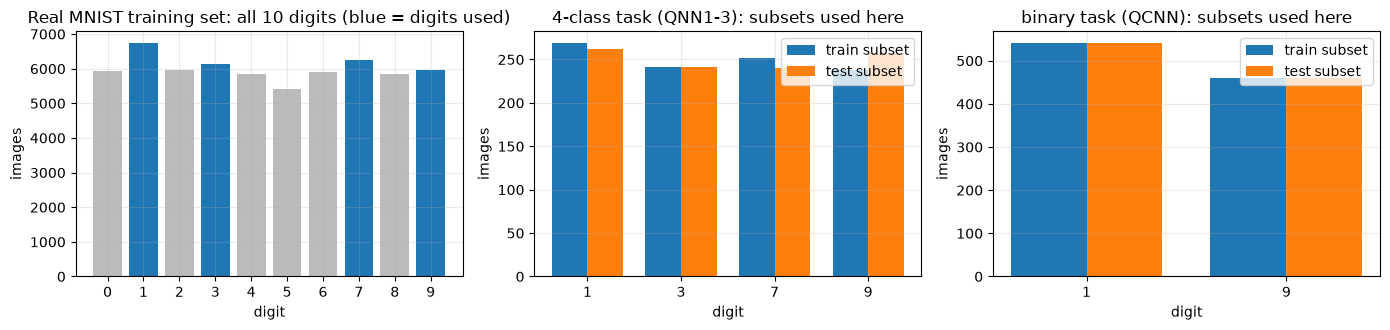

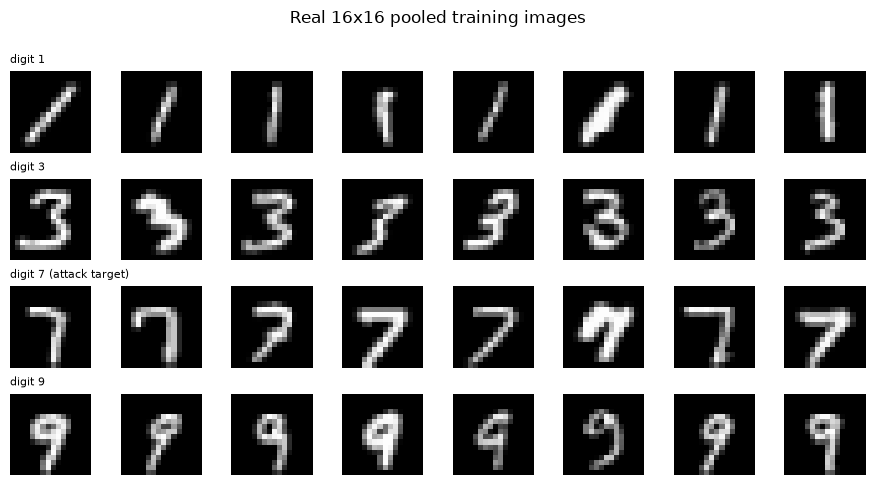

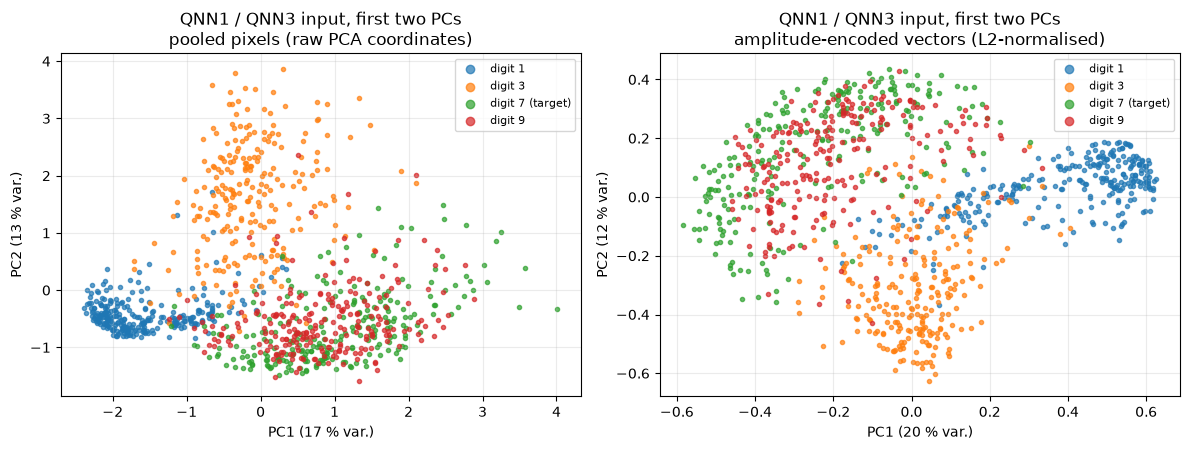

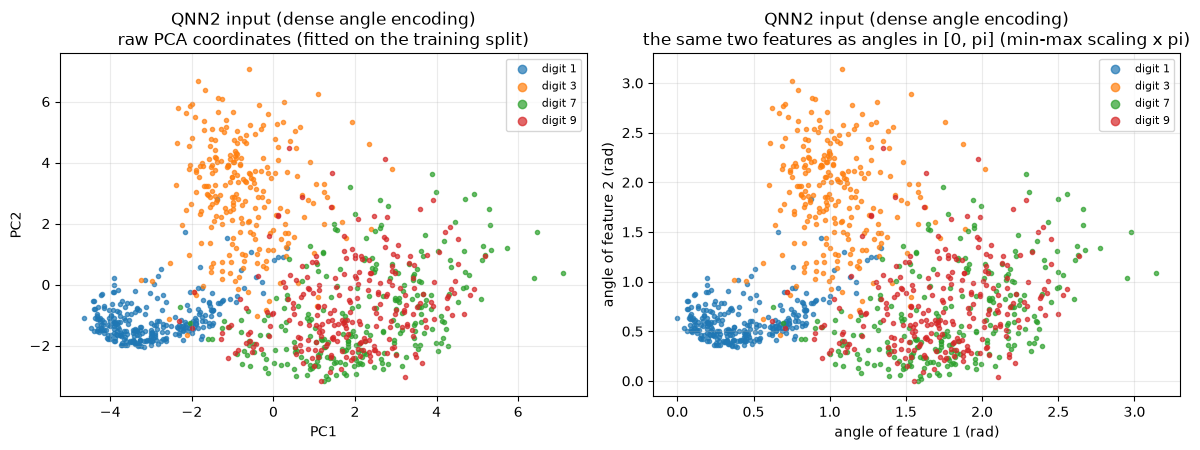

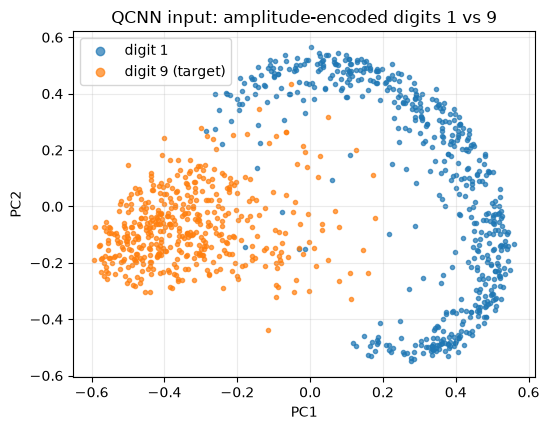

In [5]:
print("Original MNIST: train", x_tr_all.shape, "test", x_te_all.shape, "| pixel type", x_tr_all.dtype, "range", x_tr_all.min(), "-", x_tr_all.max())
print("Original label values (full training set):", dict(zip(*[a.tolist() for a in np.unique(y_tr_all, return_counts=True)])))
print("Original label values (full test set)    :", dict(zip(*[a.tolist() for a in np.unique(y_te_all, return_counts=True)])))
feat_pix = [f"px_{r}_{c}" for r in range(16) for c in range(16)]
feat_pca = [f"pc_{k + 1}" for k in range(16)]
print(f"\nView 'pix4'/'pixqc': {len(feat_pix)} features per image (pooled pixel intensities in [0,1]); first names {feat_pix[:3]} ... last {feat_pix[-1]}")
print(f"View 'pca4': {len(feat_pca)} features per image (PCA components of the 28x28 image, min-max scaled to [0,1]); names {feat_pca[:3]} ... {feat_pca[-1]}")
for k_, v_ in DS.items():
    print(f"{k_:6s} train {tuple(v_['Xtr'].shape)} test {tuple(v_['Xte'].shape)} | train label counts", dict(zip(v_["names"], np.bincount(v_["ytr"].numpy(), minlength=v_["k"]).tolist())),
          "| test", dict(zip(v_["names"], np.bincount(v_["yte"].numpy(), minlength=v_["k"]).tolist())), "| target digit", v_["names"][v_["target"]])

# ---- class distributions of the real data ----
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
cnt_all = np.bincount(y_tr_all, minlength=10)
ax[0].bar(range(10), cnt_all, color=["#1f77b4" if k in CLASSES else "#bbbbbb" for k in range(10)])
ax[0].set(title="Real MNIST training set: all 10 digits (blue = digits used)", xlabel="digit", ylabel="images"); ax[0].set_xticks(range(10))
w_ = 0.38
for a_, key, ttl in [(ax[1], "pix4", "4-class task (QNN1-3)"), (ax[2], "pixqc", "binary task (QCNN)")]:
    k_ = DS[key]["k"]; names_ = DS[key]["names"]
    a_.bar(np.arange(k_) - w_ / 2, np.bincount(DS[key]["ytr"].numpy(), minlength=k_), w_, label="train subset")
    a_.bar(np.arange(k_) + w_ / 2, np.bincount(DS[key]["yte"].numpy(), minlength=k_), w_, label="test subset")
    a_.set(title=f"{ttl}: subsets used here", xlabel="digit", ylabel="images"); a_.set_xticks(range(k_)); a_.set_xticklabels(names_); a_.legend()
plt.tight_layout(); plt.show()

# ---- real example images ----
ds4 = DS["pix4"]
fig, ax = plt.subplots(ds4["k"], 8, figsize=(9, 1.2 * ds4["k"]))
for c in range(ds4["k"]):
    ii = np.where(ds4["ytr"].numpy() == c)[0][:8]
    for k, i in enumerate(ii):
        ax[c, k].imshow(ds4["Xtr"][i].reshape(16, 16), cmap="gray", vmin=0, vmax=1); ax[c, k].axis("off")
    ax[c, 0].set_title(f"digit {ds4['names'][c]}" + (" (attack target)" if c == ds4["target"] else ""), fontsize=8, loc="left")
fig.suptitle("Real 16x16 pooled training images", y=1.0); plt.tight_layout(); plt.show()

# ---- 2-D scatter plots of the REAL observations, coloured by ground-truth digit; PCA fitted on the training split only ----
amp = lambda M: M / np.linalg.norm(M, axis=1, keepdims=True)
cols = plt.cm.tab10(np.arange(10))
A_tr = DS["pix4"]["Xtr"].numpy(); y4 = DS["pix4"]["ytr"].numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for k, (nm, ftr) in enumerate([("pooled pixels (raw PCA coordinates)", A_tr), ("amplitude-encoded vectors (L2-normalised)", amp(A_tr))]):
    pc = PCA(n_components=2, random_state=SEED).fit(ftr); Z = pc.transform(ftr)
    for c in range(DS["pix4"]["k"]):
        m = y4 == c
        ax[k].scatter(Z[m, 0], Z[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {DS['pix4']['names'][c]}" + (" (target)" if c == DS["pix4"]["target"] else ""))
    ax[k].set(title=f"QNN1 / QNN3 input, first two PCs\n{nm}", xlabel=f"PC1 ({100 * pc.explained_variance_ratio_[0]:.0f} % var.)", ylabel=f"PC2 ({100 * pc.explained_variance_ratio_[1]:.0f} % var.)")
    ax[k].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

# QNN2 uses angle encoding: raw PCA coordinates (fitted on the training split) and then the same coordinates scaled to [0, pi]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ang = np.pi * DS["pca4"]["Xtr"].numpy()
for k, (nm, Z, xl) in enumerate([("raw PCA coordinates (fitted on the training split)", Z_tr[:, :2], "PC1"), ("the same two features as angles in [0, pi] (min-max scaling x pi)", ang[:, :2], "angle of feature 1 (rad)")]):
    for c in range(DS["pca4"]["k"]):
        m = y4 == c
        ax[k].scatter(Z[m, 0], Z[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {DS['pca4']['names'][c]}")
    ax[k].set(title=f"QNN2 input (dense angle encoding)\n{nm}", xlabel=xl, ylabel="PC2" if k == 0 else "angle of feature 2 (rad)"); ax[k].legend(markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

# QCNN: digits 1 vs 9
dq = DS["pixqc"]; pcq = PCA(n_components=2, random_state=SEED).fit(amp(dq["Xtr"].numpy())); Zq = pcq.transform(amp(dq["Xtr"].numpy()))
fig, ax = plt.subplots(figsize=(5.6, 4.4))
for c in range(2):
    m = dq["ytr"].numpy() == c; ax.scatter(Zq[m, 0], Zq[m, 1], s=9, color=cols[c], alpha=0.7, label=f"digit {dq['names'][c]}" + (" (target)" if c == dq["target"] else ""))
ax.set(title="QCNN input: amplitude-encoded digits 1 vs 9", xlabel="PC1", ylabel="PC2"); ax.legend(markerscale=2); plt.tight_layout(); plt.show()

## 2. Classical baselines on identical inputs

A yardstick before any quantum number: a random forest and an RBF support-vector machine trained on exactly the same inputs as the quantum models (the L2-normalised 256 pooled pixels, the 16 PCA features of QNN2) and the same train / test images. They are *clean* models; they say how hard the tasks are.
Section 12 later gives them the poisoned training sets too.

In [6]:
t0 = time.time()
CLASSICAL = {}
for key, nm in [("pix4", "4 digits, 256 pixels (L2-normalised)"), ("pca4", "4 digits, 16 PCA features"), ("pixqc", "digits 1 vs 9, 256 pixels (L2-normalised)")]:
    d_ = DS[key]; f = (lambda M: M / np.linalg.norm(M, axis=1, keepdims=True)) if key != "pca4" else (lambda M: M)
    Xa, Xb = f(d_["Xtr"].numpy()), f(d_["Xte"].numpy())
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(Xa, d_["ytr"].numpy())
    sv = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(Xa, d_["ytr"].numpy())
    CLASSICAL[key] = {"RandomForest": float(100 * (rf.predict(Xb) == d_["yte"].numpy()).mean()), "SVC (rbf)": float(100 * (sv.predict(Xb) == d_["yte"].numpy()).mean())}
    print(f"{nm:44s}", {k: round(v, 2) for k, v in CLASSICAL[key].items()})
print(f"{time.time() - t0:.1f} s")

4 digits, 256 pixels (L2-normalised)         {'RandomForest': 96.7, 'SVC (rbf)': 97.8}


4 digits, 16 PCA features                    {'RandomForest': 95.4, 'SVC (rbf)': 97.0}


digits 1 vs 9, 256 pixels (L2-normalised)    {'RandomForest': 99.5, 'SVC (rbf)': 99.8}
11.5 s


## 3. The building blocks: four victim circuits

**Simulator.** The paper simulates its circuits with PennyLane. Here every circuit exists twice: as a PennyLane `QNode` (used for the circuit drawings and for correctness checks) and as a compact exact PyTorch state-vector simulator (used for training because it is much faster on a CPU and differentiable in PyTorch).
The two are checked to agree to 1e-4 in the circuit section; the parameter-shift gradient used in the paper is checked against the back-propagated gradient used here.

**Four victims.** QNN1, QNN2, QNN3 and the QCNN, each with 8 qubits (see the table at the top for the gate lists). The attack never sees their angles: the adversary trains his own proxy.

**The attack code** (`fuzzy_admix`, `make_trigger`, `poison`, ...) follows Algorithm 1, read the docstrings and the `# CHOICE` comments. One implementation detail: a *proxy* is collapsed into a single 256x256 unitary once, so that the thousands of gradient evaluations of Algorithm 1 are cheap.

*Note on the learning rate.* In a short pre-test (not part of this notebook, so not reproducible from its outputs) the paper's 0.003 and 0.01 gave similar accuracy after 40 epochs for QNN1 and QNN3, while QNN2 and the QCNN were clearly better with 0.01; every victim here therefore uses 0.01.

In [7]:
DIM = 2 ** NQ                          # 256 amplitudes

# ------------------------------------------------------------------------------------------------
# The four victims of Section 5.1.  "enc" = how the classical input becomes a quantum state.
#   QNN1 [7]  circuit-centric classifier (Schuld et al.): Rot(phi,theta,omega) = RZ-RY-RZ on every qubit + CNOT(q, q+r), r changes with the layer
#   QNN2 [32] variational classifier after Farhi-Neven, angle encoding (here: DENSE angle encoding of LaRose-Coyle [33], 2 features per qubit)
#   QNN3 [45] quantum circuit learning (Mitarai et al.): fixed random transverse-field Ising unitary U_ent, then RX-RZ-RX on every qubit
#   QCNN [46] quantum convolutional network (Cong et al.): conv / pool blocks 8 -> 4 -> 2 -> 1 qubits
# ------------------------------------------------------------------------------------------------
SPEC = {
    "QNN1": dict(enc="amp",   ds="pix4",  rot="ZYZ", ent="cnot_range", order="rot_ent", out=[0, 1], k=4),
    "QNN2": dict(enc="dense", ds="pca4",  rot="XYZ", ent="cnot_ring",  order="ent_rot", out=[0, 1], k=4),
    "QNN3": dict(enc="amp",   ds="pix4",  rot="XZX", ent="unitary",    order="ent_rot", out=[0, 1], k=4),
    "QCNN": dict(enc="amp",   ds="pixqc", out=[7], k=2),
}
VICTIMS = list(SPEC)
def _bits(j, q):                       # value of qubit q (wire 0 = most significant bit) in basis state j
    return (j >> (NQ - 1 - q)) & 1

_PERM_CACHE = {}
def cnot_src(pairs):
    """Permutation of a sequence of CNOT(control, target) gates: new_psi[k] = psi[src[k]]."""
    key = tuple(pairs)
    if key not in _PERM_CACHE:
        src = np.arange(DIM)
        for j in range(DIM):
            bits = [_bits(j, q) for q in range(NQ)]
            for c, t in pairs:
                if bits[c]:
                    bits[t] ^= 1
            k = 0
            for q in range(NQ):
                k = (k << 1) | bits[q]
            src[k] = j
        _PERM_CACHE[key] = torch.tensor(src, dtype=torch.long)
    return _PERM_CACHE[key]

def ent_pairs(name, l):
    if name == "QNN1":
        r = (l % (NQ - 1)) + 1
        return [(q, (q + r) % NQ) for q in range(NQ)]
    return [(q, (q + 1) % NQ) for q in range(NQ)]                # ring (QNN2)

# QNN3's fixed random entangler: U_ent = exp(-i T H), H = sum_j a_j X_j + sum_{j<k} J_jk Z_j Z_k, a_j, J_jk ~ U[-1, 1]  (Mitarai et al. 2018)
def make_uent(seed=SEED):
    r = np.random.default_rng(seed)
    X = np.array([[0, 1], [1, 0]], complex); Z = np.diag([1.0, -1.0]).astype(complex); I2 = np.eye(2, dtype=complex)
    def op(single, q):
        m = np.array([[1.0 + 0j]])
        for k in range(NQ): m = np.kron(m, single if k == q else I2)
        return m
    H = sum(r.uniform(-1, 1) * op(X, j) for j in range(NQ))
    for j in range(NQ):
        for k in range(j + 1, NQ): H = H + r.uniform(-1, 1) * op(Z, j) @ op(Z, k)
    ev, V = np.linalg.eigh(H)
    return (V * np.exp(-1j * UENT_T * ev)) @ V.conj().T
UENT = make_uent()
assert np.allclose(UENT @ UENT.conj().T, np.eye(DIM), atol=1e-8)
UENT_T_ = torch.tensor(UENT.T, dtype=torch.complex64)             # psi_row @ UENT^T applies U_ent to each row state

def _rot(kind, t):
    """Batched single-qubit rotation RX/RY/RZ; t has any shape S, result S + (2, 2) complex64."""
    c, s = torch.cos(t / 2), torch.sin(t / 2); z = torch.zeros_like(t)
    if kind == "X":
        m = torch.stack([c + 0j, -1j * s, -1j * s, c + 0j], -1)
    elif kind == "Y":
        m = torch.stack([c + 0j, -s + 0j, s + 0j, c + 0j], -1)
    else:
        e = torch.exp(-0.5j * t); m = torch.stack([e, z + 0j, z + 0j, e.conj()], -1)
    return m.reshape(*t.shape, 2, 2)

def _kron_tree(m):
    """m: (L, n, 2, 2) -> (L, 2^n, 2^n): Kronecker product over the qubit axis (first qubit = most significant)."""
    while m.shape[1] > 1:
        a, b = m[:, 0::2], m[:, 1::2]
        m = torch.einsum("lqij,lqkm->lqikjm", a, b).reshape(m.shape[0], m.shape[1] // 2, a.shape[2] * b.shape[2], a.shape[3] * b.shape[3])
    return m[:, 0]

def rot_unitaries(w, rot):
    """One layer of single-qubit rotations on all 8 qubits, as two Kronecker products (qubits 0-3 and qubits 4-7): returns (A, B), each (L, 16, 16)."""
    us = _rot(rot[0], w[..., 0])
    for k in range(1, len(rot)):
        us = _rot(rot[k], w[..., k]) @ us                       # gate k acts after gate k-1
    return _kron_tree(us[:, :4]), _kron_tree(us[:, 4:])

def apply_rot(psi, A, B):
    """psi (n, 256) viewed as a 16x16 matrix (rows = qubits 0-3, columns = qubits 4-7):  psi -> A psi B^T."""
    n = psi.shape[0]
    return (A @ psi.reshape(n, 16, 16) @ B.T).reshape(n, DIM)

# ---------------- input encodings (differentiable in the input) ----------------
def encode(x, enc):
    if enc == "amp":                                            # amplitude encoding: image / ||image||
        return (x / x.norm(dim=1, keepdim=True).clamp_min(1e-8)).to(torch.complex64)
    # dense angle encoding (LaRose & Coyle): qubit q = RZ(2 pi x[2q+1]) RY(pi x[2q]) |0>
    th, ph = np.pi * x[:, 0::2], 2 * np.pi * x[:, 1::2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    q0 = (c * torch.exp(-0.5j * ph)).to(torch.complex64); q1 = (s * torch.exp(0.5j * ph)).to(torch.complex64)
    st = torch.stack([q0, q1], -1)                              # (B, 8, 2)
    out = st[:, 0]
    for q in range(1, NQ):
        out = torch.einsum("bi,bj->bij", out, st[:, q]).reshape(len(x), -1)
    return out

# ---------------- QCNN: gates applied to a batch of 8-qubit states ----------------
def apply_gate(psi, M, wires):
    k = len(wires); B = psi.shape[0]
    src = [1 + q for q in wires]
    t = torch.movedim(psi.reshape(B, *([2] * NQ)), src, list(range(1, 1 + k)))
    rest = t.shape[1 + k:]
    t = torch.einsum("ij,bjr->bir", M, t.reshape(B, 2 ** k, -1)).reshape(B, *([2] * k), *rest)
    return torch.movedim(t, list(range(1, 1 + k)), src).reshape(B, DIM)

_I = lambda: torch.eye(2, dtype=torch.complex64)
def _g1(kind, t): return _rot(kind, t)
CNOT_M = torch.tensor([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=torch.complex64)
X_M = torch.tensor([[0, 1], [1, 0]], dtype=torch.complex64)
def _crz(t):
    e = torch.exp(-0.5j * t); return torch.diag(torch.stack([torch.ones_like(e), torch.ones_like(e), e, e.conj()]))
def _crx(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2); M = torch.eye(4, dtype=torch.complex64)
    M = M.clone(); M[2, 2] = c + 0j; M[3, 3] = c + 0j; M[2, 3] = -1j * s; M[3, 2] = -1j * s
    return M

def qcnn_ops():
    """The QCNN as an ordered gate list [(name, wires, param_index or None)], shared by the simulator and the PennyLane QNode.
    conv block (8 angles, shared by all pairs of one level): RZ-RY-RZ on a, RZ-RY-RZ on b, CNOT(a,b), RY a, RY b, CNOT(b,a)
    pool block (2 angles): CRZ(a->b), X(a), CRX(a->b); qubit a is then discarded (only b is used further)."""
    ops, active, p = [], list(range(NQ)), 0
    for lvl in range(3):
        base = p
        pairs = [(active[i], active[i + 1]) for i in range(0, len(active), 2)]
        pairs_odd = [(active[i], active[i + 1]) for i in range(1, len(active) - 1, 2)]
        for (a, b) in pairs + pairs_odd:
            for kind, w_, idx in [("RZ", a, 0), ("RY", a, 1), ("RZ", a, 2), ("RZ", b, 3), ("RY", b, 4), ("RZ", b, 5)]:
                ops.append((kind, [w_], base + idx))
            ops += [("CNOT", [a, b], None), ("RY", [a], base + 6), ("RY", [b], base + 7), ("CNOT", [b, a], None)]
        p += 8
        for (a, b) in pairs:
            ops += [("CRZ", [a, b], p), ("X", [a], None), ("CRX", [a, b], p + 1)]
        p += 2
        active = [b for (_, b) in pairs]
    return ops, p
QCNN_OPS, QCNN_NPAR = qcnn_ops()

CNOT_BA = torch.tensor([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=torch.complex64)   # control = second qubit
def _k2(a, b): return torch.kron(a.contiguous(), b.contiguous())
def qcnn_blocks():
    """Same gates as QCNN_OPS, grouped per block so that each conv / pool block is ONE 4x4 matrix (faster to simulate; checked against the QNode)."""
    blocks, active, p = [], list(range(NQ)), 0
    for lvl in range(3):
        base = p
        pairs = [(active[i], active[i + 1]) for i in range(0, len(active), 2)]
        pairs_odd = [(active[i], active[i + 1]) for i in range(1, len(active) - 1, 2)]
        blocks += [("conv", [a, b], base) for (a, b) in pairs + pairs_odd]
        p += 8
        blocks += [("pool", [a, b], p) for (a, b) in pairs]
        p += 2
        active = [b for (_, b) in pairs]
    return blocks
QCNN_BLOCKS = qcnn_blocks()

def qcnn_apply(psi, w):
    cache = {}
    for kind, wires, i0 in QCNN_BLOCKS:
        if i0 not in cache:
            if kind == "conv":
                Ua = _rot("Z", w[i0 + 2]) @ _rot("Y", w[i0 + 1]) @ _rot("Z", w[i0 + 0])
                Ub = _rot("Z", w[i0 + 5]) @ _rot("Y", w[i0 + 4]) @ _rot("Z", w[i0 + 3])
                cache[i0] = CNOT_BA @ _k2(_rot("Y", w[i0 + 6]), _rot("Y", w[i0 + 7])) @ CNOT_M @ _k2(Ua, Ub)
            else:
                cache[i0] = _crx(w[i0 + 1]) @ _k2(X_M, _I()) @ _crz(w[i0])
        psi = apply_gate(psi, cache[i0], wires)
    return psi

# ---------------- forward pass of every victim ----------------
def n_params(name, L=None):
    if name == "QCNN": return QCNN_NPAR
    return L * NQ * 3

def apply_circuit(psi, w, name):
    """Parameterised part of the circuit on a batch of states psi (B, 256)."""
    if name == "QCNN": return qcnn_apply(psi, w)
    spec = SPEC[name]; L = w.shape[0]
    UA, UB = rot_unitaries(w, spec["rot"])
    for l in range(L):
        if spec["order"] == "rot_ent":
            psi = apply_rot(psi, UA[l], UB[l])
            psi = torch.index_select(psi, 1, cnot_src(ent_pairs(name, l)))
        else:
            psi = torch.index_select(psi, 1, cnot_src(ent_pairs(name, l))) if spec["ent"] == "cnot_ring" else psi @ UENT_T_
            psi = apply_rot(psi, UA[l], UB[l])
    return psi

def out_probs(psi, name):
    """Class probabilities = measurement probabilities of the read-out qubits (4 classes: qubits 0,1; QCNN: qubit 7)."""
    p = psi.real ** 2 + psi.imag ** 2
    if name == "QCNN": return p.reshape(len(p), DIM // 2, 2).sum(1)
    return p.reshape(len(p), 4, DIM // 4).sum(-1)

def model_probs(name, w, x):
    return out_probs(apply_circuit(encode(x, SPEC[name]["enc"]), w, name), name)

def init_weights(name, seed):
    g = torch.Generator().manual_seed(seed)
    n = (n_params(name),) if name == "QCNN" else (LAYERS[name], NQ, 3)
    return (torch.rand(*n, generator=g) * 2 * np.pi).requires_grad_(True)     # CHOICE: uniform [0, 2 pi)

# ---------------- the same circuits as PennyLane QNodes (drawings + equivalence checks) ----------------
_GATE = {"X": qml.RX, "Y": qml.RY, "Z": qml.RZ}
def make_pl_qnn(name, diff_method="backprop"):
    spec = SPEC[name]; dev = qml.device("default.qubit", wires=NQ)
    @qml.qnode(dev, interface="torch", diff_method=diff_method)
    def circuit(x, w):
        if spec["enc"] == "amp":
            qml.AmplitudeEmbedding(x, wires=range(NQ), normalize=True)
        else:
            for q in range(NQ):
                qml.RY(np.pi * x[2 * q], wires=q); qml.RZ(2 * np.pi * x[2 * q + 1], wires=q)
        if name == "QCNN":
            for g_, wires, idx in QCNN_OPS:
                if g_ in ("RX", "RY", "RZ"): _GATE[g_[1]](w[idx], wires=wires[0])
                elif g_ == "CNOT": qml.CNOT(wires=wires)
                elif g_ == "X": qml.PauliX(wires=wires[0])
                elif g_ == "CRZ": qml.CRZ(w[idx], wires=wires)
                else: qml.CRX(w[idx], wires=wires)
            return qml.probs(wires=spec["out"])
        for l in range(w.shape[0]):
            def rot_block():
                for q in range(NQ):
                    for k, kind in enumerate(spec["rot"]): _GATE[kind](w[l, q, k], wires=q)
            def ent_block():
                if spec["ent"] == "unitary": qml.QubitUnitary(UENT, wires=range(NQ))
                else:
                    for c, t in ent_pairs(name, l): qml.CNOT(wires=[c, t])
            if spec["order"] == "rot_ent": rot_block(); ent_block()
            else: ent_block(); rot_block()
        return qml.probs(wires=spec["out"])
    return circuit

In [8]:
# ---------------- training, prediction, metrics ----------------
def qce_loss(p, y):
    """Quantum cross-entropy: -log of the measurement probability of the true class (the QNN output IS a probability vector)."""
    return -torch.log(p.gather(1, y[:, None]).clamp_min(1e-8)).mean()

def train_qnn(name, X, y, epochs, seed, lr=None, log=0, w0=None):
    """Adam training of one victim (batch BATCH). Gradients by exact back-propagation through the simulator: they equal the
    parameter-shift gradients of the paper (checked in the circuit section). Returns the trained angles."""
    lr = lr or LR
    rg = np.random.default_rng(seed)
    w = init_weights(name, seed) if w0 is None else w0.clone().requires_grad_(True)
    opt = torch.optim.Adam([w], lr=lr)
    n = len(X)
    for ep in range(epochs):
        idx = rg.permutation(n); tot = 0.0; nb = 0
        for s in range(0, n - BATCH + 1, BATCH):
            b = idx[s:s + BATCH]
            loss = qce_loss(model_probs(name, w, X[b]), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        if log and ((ep + 1) % log == 0 or ep == 0):
            print(f"    epoch {ep + 1:3d}/{epochs}  train loss {tot / max(nb, 1):.3f}", flush=True)
    return w.detach()

@torch.no_grad()
def predict(name, w, X, bs=500):
    return torch.cat([model_probs(name, w, X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])

def clip01(x): return x.clamp(0, 1)

def metrics(name, w, ds, trig=None):
    """CA = accuracy on clean test data. ASR = share of NON-target test samples that the model assigns to the target class once the trigger is added."""
    ca = 100 * (predict(name, w, ds["Xte"]) == ds["yte"]).float().mean().item()
    if trig is None: return dict(CA=ca, ASR=float("nan"))
    nt = ds["yte"] != ds["target"]
    asr = 100 * (predict(name, w, trig["test"](ds["Xte"][nt])) == ds["target"]).float().mean().item()
    return dict(CA=ca, ASR=asr)

### The attack code: fuzzy admix, proxies, Algorithm 1, baseline, poisoning (Section 4 of the paper)

In [9]:
# =========================== the attack of the paper (Section 4) ===========================

# ---------------- fuzzy admix, Eq. (4)-(5) ----------------
def fuzzy_admix(x, Xt, c, sigma, rg, n=N_ADMIX):
    """x~ = mu(x) x + (1/n) sum_i nu(x) x_t^i,  mu(x) = exp(-(x-c)^2 / sigma^2),  nu = 1 - mu  (applied element-wise to the features / pixels).
    Unlike mixup, the label stays the label of x."""
    xt = Xt[rg.choice(len(Xt), n, replace=False)].mean(0, keepdim=True)
    mu = torch.exp(-((x - c) ** 2) / sigma ** 2)
    return mu * x + (1 - mu) * xt

# ---------------- proxy models ----------------
class QProxy:
    """A trained QNN of the victim's architecture used as the adversary's proxy. The whole circuit is collapsed into one
    256x256 unitary R once (psi_out = psi_in @ R), so that millions of cheap, differentiable forward passes are possible."""
    def __init__(self, name, w):
        self.name = name
        with torch.no_grad():
            self.R = apply_circuit(torch.eye(DIM, dtype=torch.complex64), w, name)
        self.enc = SPEC[name]["enc"]
    def __call__(self, x):                                      # log-probabilities (B, k)
        return torch.log(out_probs(encode(x, self.enc) @ self.R, self.name).clamp_min(1e-8))

class FNNProxy(nn.Module):
    """Classical feed-forward proxy for an adversary without quantum resources (Section 5.4): input -> 64 ReLU -> k."""
    def __init__(self, d, k):
        super().__init__(); self.net = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, k))   # CHOICE: width 64
    def forward(self, x): return F.log_softmax(self.net(x), 1)

def train_fnn(X, y, k, seed, epochs=30):
    torch.manual_seed(seed); m = FNNProxy(X.shape[1], k); opt = torch.optim.Adam(m.parameters(), lr=0.01); rg = np.random.default_rng(seed)
    for ep in range(epochs):
        idx = rg.permutation(len(X))
        for s in range(0, len(X) - BATCH + 1, BATCH):
            b = idx[s:s + BATCH]; loss = F.nll_loss(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    for p in m.parameters(): p.requires_grad_(False)
    return m.eval()

PROXIES = {}
def get_proxy(victim, kind, seed):
    key = (victim, kind, seed)
    if key not in PROXIES:
        ds = DS[SPEC[victim]["ds"]]
        if kind == "qnn":                                       # the adversary trains the SAME architecture on the data set he publishes (other random start)
            PROXIES[key] = QProxy(victim, train_qnn(victim, ds["Xtr"], ds["ytr"], EPOCHS, seed + 100))
        else:
            PROXIES[key] = train_fnn(ds["Xtr"], ds["ytr"], ds["k"], seed + 100)
    return PROXIES[key]

# ---------------- perturbation generators G(P, x, y_t) ----------------
def _grad_to_target(proxy, x, yt):
    x = x.clone().requires_grad_(True)
    F.nll_loss(proxy(x), torch.tensor([yt])).backward()
    return x.grad

def gen_fgsm(proxy, xadv, yt, eps):
    """Targeted (Q-)FGSM: one signed-gradient step towards class y_t, step = ALG_STEP * eps (small steps so that many images can vote for the trigger)."""
    return -ALG_STEP * eps * _grad_to_target(proxy, xadv, yt).sign()

def gen_bim(proxy, xadv, yt, eps, steps=BIM_STEPS):
    """Targeted (Q-)BIM: iterate the signed-gradient step (stop as soon as the proxy outputs y_t), then keep the total change inside the eps ball."""
    x = xadv.clone()
    for _ in range(steps):
        x = x - ALG_STEP * eps * _grad_to_target(proxy, x, yt).sign()
        if int(proxy(x).argmax()) == yt: break
    return (x - xadv).clamp(-eps, eps)

GEN = {"Q-FGSM": gen_fgsm, "Q-BIM": gen_bim, "FGSM": gen_fgsm, "PGD": gen_bim}     # with a classical FNN proxy the same loops are called FGSM / PGD

# ---------------- Algorithm 1: trigger generation ----------------
def make_trigger(proxy, Xut, Xt, yt, g_name, eps=EPS, cs=CS, use_admix=True, seed=SEED, imax=IMAX, n_trig=N_TRIG, fool_t=FOOL_T):
    """Universal trigger delta (||delta||_inf <= eps). Loop over non-target samples: admix them with target-class samples, add the current trigger,
    and for every sample the proxy still does not assign to y_t add the perturbation found by G, projected back into the eps ball.
    Stops when the fooling rate on the (un-mixed) non-target images exceeds `fool_t` or after `imax` rounds."""
    rg = np.random.default_rng(seed + 11); G = GEN[g_name]
    delta = torch.zeros(1, Xut.shape[1]); hist = []
    for j in range(imax):
        for i in rg.permutation(len(Xut))[:n_trig]:
            x = Xut[i:i + 1]
            xm = fuzzy_admix(x, Xt, cs[0], cs[1], rg) if use_admix else x      # CHOICE: without fuzzy admix the image itself is used
            xadv = xm + delta                                                   # CHOICE: no clipping to [0, 1]: both encodings accept any real input (the paper writes x + delta)
            with torch.no_grad():
                if int(proxy(xadv).argmax()) == yt: continue
            delta = (delta + G(proxy, xadv, yt, eps)).clamp(-eps, eps)           # Proj onto the l_inf ball
        with torch.no_grad():
            f = (proxy(Xut + delta).argmax(1) == yt).float().mean().item()
        hist.append(f)
        if f > fool_t: break
    return delta, hist

# ---------------- baseline attack: clean-label backdoor of Turner et al. (patch + l2-bounded adversarial perturbation) ----------------
def add_patch(X, size=PATCH):
    """Fixed square trigger in the lower right corner of the image (16x16 pixels) or of the 4x4 feature map (QNN2): value 1."""
    X = X.clone(); s = int(round(np.sqrt(X.shape[1])))
    G = X.reshape(len(X), s, s); G[:, -size:, -size:] = 1.0
    return G.reshape(len(X), -1)

def l2_pgd(proxy, X, y, radius=L2_BASE, steps=10):
    """Untargeted l2 PGD: make the TARGET-class training images hard to classify (Turner et al.'s way of forcing the model to rely on the patch)."""
    x0 = X.clone(); x = X.clone(); a = 2.5 * radius / steps
    for _ in range(steps):
        x.requires_grad_(True); F.nll_loss(proxy(x), y).backward()
        g = x.grad; g = g / g.flatten(1).norm(dim=1, keepdim=True).clamp_min(1e-12)
        x = (x.detach() + a * g)
        d = x - x0; n = d.flatten(1).norm(dim=1, keepdim=True).clamp_min(1e-12)
        x = clip01(x0 + d * torch.clamp(radius / n, max=1.0))
    return x.detach()

def universal_trigger(delta):
    f = lambda X: X + delta                                     # x' = x + delta (no clipping, see make_trigger)
    return dict(test=f, train=lambda X, y: f(X), delta=delta)

def baseline_trigger(proxy):
    return dict(test=add_patch, train=lambda X, y: add_patch(l2_pgd(proxy, X, y)), delta=None)

TRIGS = {}
def get_trigger(victim, attack, seed=SEED, eps=EPS, cs=CS, kind="qnn", use_admix=True):
    key = (victim, attack, seed, eps, cs, kind, use_admix)
    if key not in TRIGS:
        ds = DS[SPEC[victim]["ds"]]; proxy = get_proxy(victim, kind, seed)
        if attack == "Baseline":
            TRIGS[key] = baseline_trigger(proxy)
        else:
            Xut = ds["Xtr"][ds["ytr"] != ds["target"]]; Xt = ds["Xtr"][ds["ytr"] == ds["target"]]
            delta, hist = make_trigger(proxy, Xut, Xt, ds["target"], attack, eps, cs, use_admix, seed)
            TRIGS[key] = dict(universal_trigger(delta), hist=hist)
        TRIGS[key]["key"] = key
    return TRIGS[key]

# ---------------- poisoning and victim training ----------------
def poison(ds, trig, rate, seed):
    """Clean-label poisoning: `rate` x (number of target-class training samples) of them get the trigger; their labels are NOT changed."""
    r = np.random.default_rng(seed + 7)
    cand = np.where(ds["ytr"].numpy() == ds["target"])[0]
    idx = r.choice(cand, int(round(rate * len(cand))), replace=False)
    Xp = ds["Xtr"].clone()
    if len(idx): Xp[idx] = trig["train"](ds["Xtr"][idx], ds["ytr"][idx])
    return Xp, idx

MODELS = {}
def get_model(victim, attack=None, rate=0.0, seed=SEED, **tkw):
    """Trained angles of a victim. rate = 0 (or attack None) is the clean model; same seed -> same initial angles for clean and backdoored models."""
    ds = DS[SPEC[victim]["ds"]]
    if rate == 0 or attack is None:
        key = (victim, 0.0, seed)
    else:
        trig = get_trigger(victim, attack, seed, **tkw); key = (victim, rate, seed, trig["key"])
    if key not in MODELS:
        Xp = ds["Xtr"] if len(key) == 3 else poison(ds, trig, rate, seed)[0]
        MODELS[key] = train_qnn(victim, Xp, ds["ytr"], EPOCHS, seed)
    return MODELS[key]

def run_cell(victim, attack, rate, seed=SEED, **tkw):
    """CA / ASR of one (victim, attack, poisoning ratio, seed) cell."""
    ds = DS[SPEC[victim]["ds"]]
    return metrics(victim, get_model(victim, attack, rate, seed, **tkw), ds, get_trigger(victim, attack, seed, **tkw))

### The clean victims

Each victim is first trained on the clean training set. The table lists its size and clean test accuracy next to the classical baselines of section 2 (the paper's QNN3 reaches about 86.5 % CA).

In [10]:
rows = []
t_all = time.time()
for v in VICTIMS:
    t0 = time.time(); w = get_model(v); ds = DS[SPEC[v]["ds"]]
    m = metrics(v, w, ds)
    rows.append(dict(victim=v, qubits=NQ, layers=LAYERS.get(v, "3 conv + 3 pool"), trainable_angles=int(w.numel()), input=SPEC[v]["enc"] + " encoding / " + SPEC[v]["ds"],
                     clean_test_acc_percent=round(m["CA"], 2), RandomForest=round(CLASSICAL[SPEC[v]["ds"]]["RandomForest"], 2), SVC_rbf=round(CLASSICAL[SPEC[v]["ds"]]["SVC (rbf)"], 2), seconds=round(time.time() - t0)))
    print(f"{v}: clean test accuracy {m['CA']:.2f} %  ({time.time() - t0:.0f} s)", flush=True)
CLEAN_TABLE = pd.DataFrame(rows).set_index("victim")
print(CLEAN_TABLE.to_string())

QNN1: clean test accuracy 91.10 %  (49 s)


QNN2: clean test accuracy 75.10 %  (21 s)


QNN3: clean test accuracy 90.10 %  (20 s)


QCNN: clean test accuracy 98.30 %  (48 s)


        qubits           layers  trainable_angles                  input  clean_test_acc_percent  RandomForest  SVC_rbf  seconds
victim                                                                                                                          
QNN1         8                8               192    amp encoding / pix4                    91.1          96.7     97.8       49
QNN2         8                8               192  dense encoding / pca4                    75.1          95.4     97.0       21
QNN3         8                5               120    amp encoding / pix4                    90.1          96.7     97.8       20
QCNN         8  3 conv + 3 pool                30   amp encoding / pixqc                    98.3          99.5     99.8       48


## 4. Fuzzy admix (Eq. 4-5, Fig. 2)

Mixing a non-target image with a few target-class images, weighted by a Gaussian *membership* of each pixel, gives data that already contain target-class features while keeping the label of the original image. Fig. 2(a) of the paper sketches the idea, Fig. 2(b) shows MNIST digits mixed with 7s.
The left panel plots `mu(x)` for the parameter sets of Table 2; the right panels show real images before and after the mix.

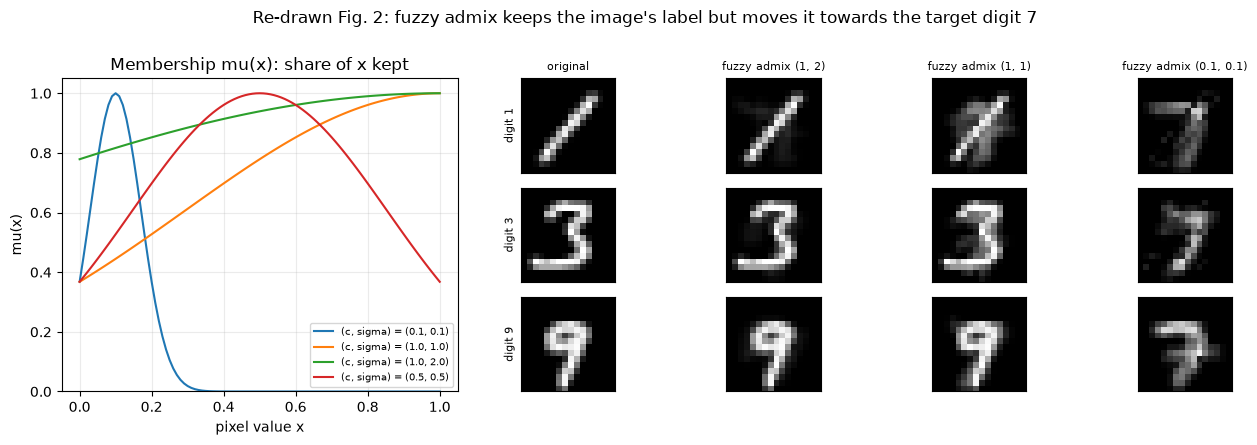

In [11]:
# Re-drawn Fig. 2: (a) the Gaussian membership function mu(x) for the parameter sets of Table 2; (b) real images before / after fuzzy admix with target digit 7
d4 = DS["pix4"]; Xt_ = d4["Xtr"][d4["ytr"] == d4["target"]]; Xnt_ = d4["Xtr"][d4["ytr"] != d4["target"]]; ynt_ = d4["ytr"][d4["ytr"] != d4["target"]]
xs_ = np.linspace(0, 1, 101)
fig = plt.figure(figsize=(13, 4.4)); gs = fig.add_gridspec(3, 6)
ax0 = fig.add_subplot(gs[:, :2])
for (c_, s_) in [(0.1, 0.1), (1.0, 1.0), (1.0, 2.0), (0.5, 0.5)]:
    ax0.plot(xs_, np.exp(-(xs_ - c_) ** 2 / s_ ** 2), label=f"(c, sigma) = ({c_}, {s_})")
ax0.set(title="Membership mu(x): share of x kept", xlabel="pixel value x", ylabel="mu(x)", ylim=(0, 1.05)); ax0.legend(fontsize=7)
rg_ = np.random.default_rng(SEED)
variants = [("original", None), ("fuzzy admix (1, 2)", (1.0, 2.0)), ("fuzzy admix (1, 1)", (1.0, 1.0)), ("fuzzy admix (0.1, 0.1)", (0.1, 0.1))]
show = [int(np.where(ynt_.numpy() == c)[0][0]) for c in (0, 1, 3)]
axes_ = [[fig.add_subplot(gs[r, 2 + k]) for k in range(4)] for r in range(3)]
for r, i in enumerate(show):
    x = Xnt_[i:i + 1]
    for k, (nm, cs_) in enumerate(variants):
        img = x if cs_ is None else fuzzy_admix(x, Xt_, cs_[0], cs_[1], rg_)
        axes_[r][k].imshow(img.reshape(16, 16), cmap="gray", vmin=0, vmax=1); axes_[r][k].set_xticks([]); axes_[r][k].set_yticks([]); axes_[r][k].grid(False)
        if r == 0: axes_[r][k].set_title(nm, fontsize=8)
    axes_[r][0].set_ylabel(f"digit {d4['names'][int(ynt_[i])]}", fontsize=8)
fig.suptitle("Re-drawn Fig. 2: fuzzy admix keeps the image's label but moves it towards the target digit 7", y=1.0); plt.tight_layout(); plt.show()

## 5. Step 1: generating the trigger (Algorithm 1)

For each victim the adversary trains a proxy QNN of the same architecture (another random start) and runs Algorithm 1 with the quantum FGSM and the quantum BIM generator. The first printed number per trigger is the **fooling rate on the proxy** per round (the loop stops when it exceeds 0.6);
the last is the **ASR on the clean victim**: how often the trigger alone, without any backdoor, already flips a non-target input of the victim to the target class (the attack's *transfer* from proxy to victim).
Fig. 3 of the paper shows an original image and its poisoned versions; the cell redraws it for QNN3 (16x16 pixels) and QNN2 (the 4x4 feature map).

QNN1  Q-FGSM: fooling rate of the QNN proxy per round [0.987] | max|delta| = 0.20 | mean|delta| = 0.135 | ASR on the CLEAN victim (transfer, no backdoor yet) = 22.8 %


QNN1  Q-BIM : fooling rate of the QNN proxy per round [0.969] | max|delta| = 0.20 | mean|delta| = 0.150 | ASR on the CLEAN victim (transfer, no backdoor yet) = 16.8 %


QNN2  Q-FGSM: fooling rate of the QNN proxy per round [0.694] | max|delta| = 0.20 | mean|delta| = 0.133 | ASR on the CLEAN victim (transfer, no backdoor yet) = 14.5 %


QNN2  Q-BIM : fooling rate of the QNN proxy per round [0.695] | max|delta| = 0.20 | mean|delta| = 0.137 | ASR on the CLEAN victim (transfer, no backdoor yet) = 25.7 %


QNN3  Q-FGSM: fooling rate of the QNN proxy per round [1.0] | max|delta| = 0.18 | mean|delta| = 0.124 | ASR on the CLEAN victim (transfer, no backdoor yet) = 17.1 %


QNN3  Q-BIM : fooling rate of the QNN proxy per round [0.971] | max|delta| = 0.16 | mean|delta| = 0.124 | ASR on the CLEAN victim (transfer, no backdoor yet) = 13.0 %


QCNN  Q-FGSM: fooling rate of the QNN proxy per round [0.998] | max|delta| = 0.14 | mean|delta| = 0.111 | ASR on the CLEAN victim (transfer, no backdoor yet) = 54.7 %


QCNN  Q-BIM : fooling rate of the QNN proxy per round [0.998] | max|delta| = 0.14 | mean|delta| = 0.120 | ASR on the CLEAN victim (transfer, no backdoor yet) = 51.9 %


trigger generation (incl. training the proxies): 132 s


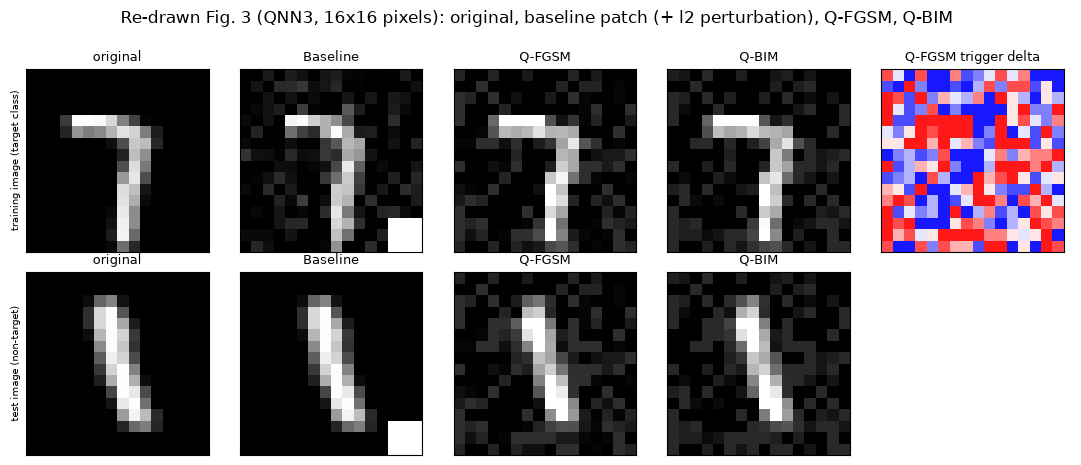

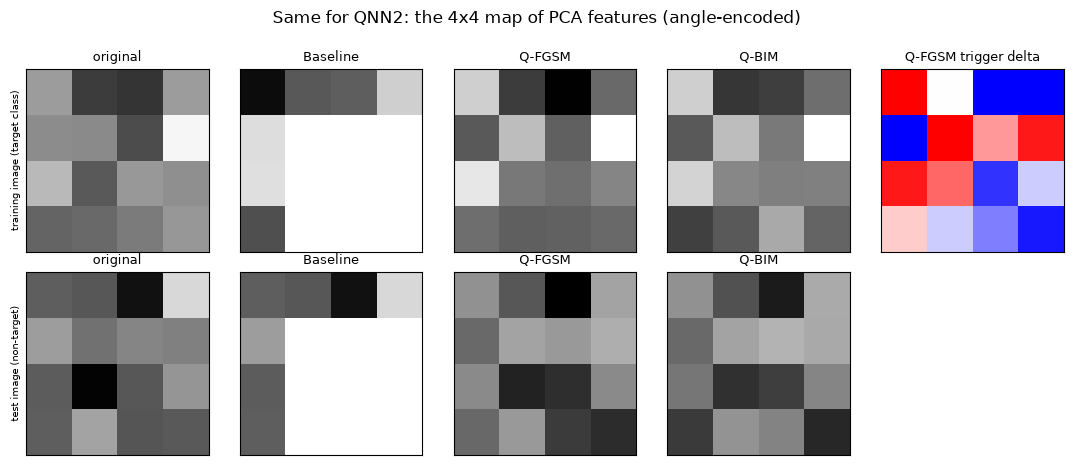

In [12]:
ATTACKS = ["Baseline", "Q-FGSM", "Q-BIM"]
ATTACK_COL = {"Baseline": "#7f7f7f", "Q-FGSM": "#d62728", "Q-BIM": "#1f77b4"}
t0 = time.time(); HIST = {}
for v in VICTIMS:
    ds = DS[SPEC[v]["ds"]]
    for at in ["Q-FGSM", "Q-BIM"]:
        tr = get_trigger(v, at)
        HIST[(v, at)] = tr["hist"]
        trf = metrics(v, get_model(v), ds, tr)["ASR"]
        print(f"{v:5s} {at:6s}: fooling rate of the QNN proxy per round {np.round(tr['hist'], 3).tolist()} | max|delta| = {float(tr['delta'].abs().max()):.2f} "
              f"| mean|delta| = {float(tr['delta'].abs().mean()):.3f} | ASR on the CLEAN victim (transfer, no backdoor yet) = {trf:.1f} %", flush=True)
print(f"trigger generation (incl. training the proxies): {time.time() - t0:.0f} s")

# Re-drawn Fig. 3: a training image of the target class (what the user trains on) and a non-target image (what the attacker presents at inference), with each trigger
def show_triggers(victim, side, title):
    ds = DS[SPEC[victim]["ds"]]; i_t = int(np.where(ds["ytr"].numpy() == ds["target"])[0][0]); i_n = int(np.where(ds["yte"].numpy() == 0)[0][0])
    fig, ax = plt.subplots(2, 5, figsize=(11, 4.6))
    for r, (nm, img, yy) in enumerate([("training image (target class)", ds["Xtr"][i_t:i_t + 1], ds["ytr"][i_t:i_t + 1]), ("test image (non-target)", ds["Xte"][i_n:i_n + 1], ds["yte"][i_n:i_n + 1])]):
        ax[r, 0].imshow(img.reshape(side, side), cmap="gray", vmin=0, vmax=1); ax[r, 0].set_title("original" if r == 0 else "original", fontsize=9)
        for k, at in enumerate(ATTACKS):
            tr = get_trigger(victim, at); xp = tr["train"](img, yy) if r == 0 else tr["test"](img)
            ax[r, k + 1].imshow(xp.reshape(side, side), cmap="gray", vmin=0, vmax=1); ax[r, k + 1].set_title(f"{at}", fontsize=9)
        ax[r, 4].axis("off"); ax[r, 0].set_ylabel(nm, fontsize=7)
    d_ = get_trigger(victim, "Q-FGSM")["delta"].reshape(side, side)
    im = ax[0, 4].imshow(d_, cmap="bwr", vmin=-EPS, vmax=EPS); ax[0, 4].set_title("Q-FGSM trigger delta", fontsize=9); ax[0, 4].axis("on")
    for a_ in ax.ravel(): a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()
show_triggers("QNN3", 16, "Re-drawn Fig. 3 (QNN3, 16x16 pixels): original, baseline patch (+ l2 perturbation), Q-FGSM, Q-BIM")
show_triggers("QNN2", 4, "Same for QNN2: the 4x4 map of PCA features (angle-encoded)")

## 6. Step 2 and 3: poisoning, backdoored victims, and Fig. 4

For every victim, attack (the clean-label baseline, Q-FGSM, Q-BIM) and poisoning ratio, a backdoored model is trained from the **same initial angles** as the clean model, on a training set in which that share of the **target-class** images carries the trigger (labels untouched). We report CA (accuracy on clean test images) and ASR (share of non-target test images that are classified as the target once the trigger is added).
Ratio 0 is the clean model (its ASR is the trigger's plain transfer).

QNN1: 18 cells done (256 s)


QNN2: 18 cells done (495 s)


QNN3: 18 cells done (728 s)


QCNN: 18 cells done (1199 s)


Fig. 4 data (this notebook); CA = clean accuracy, ASR = attack success rate, both in %

QNN1
                   CA                   ASR             
attack       Baseline Q-BIM Q-FGSM Baseline Q-BIM Q-FGSM
poison_ratio                                            
0.0              91.1  91.1   91.1      0.5  16.8   22.8
0.2              91.4  92.2   91.5     28.7  44.9   29.6
0.4              86.3  90.7   91.1     49.3  61.7   51.2
0.6              84.1  88.0   89.0     73.3  63.0   62.0
0.8              72.7  87.5   86.4     85.3  74.5   76.7
1.0              73.2  88.1   84.1     97.8  72.6   61.2

QNN2
                   CA                   ASR             
attack       Baseline Q-BIM Q-FGSM Baseline Q-BIM Q-FGSM
poison_ratio                                            
0.0              75.1  75.1   75.1     77.1  25.7   14.5
0.2              66.5  66.1   64.7     85.3  29.0   36.4
0.4              63.5  80.8   69.9     99.6  47.6   55.0
0.6              61.1  62.9   67.6     99.7  5

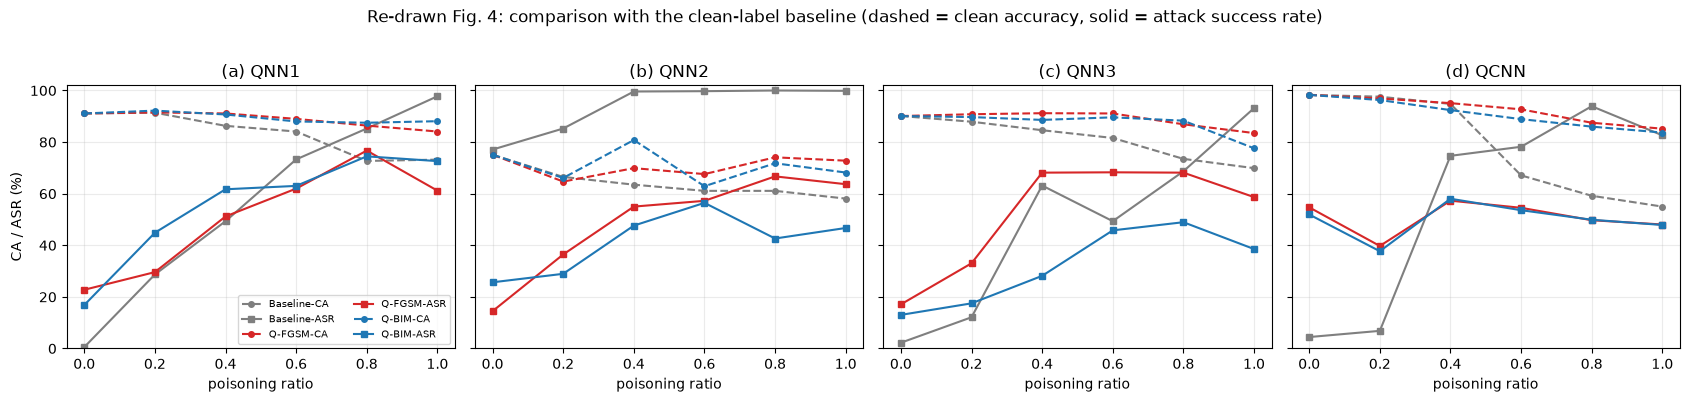

In [13]:
FIG4 = {}                                    # (victim, attack, rate) -> dict(CA, ASR)
t0 = time.time()
for v in VICTIMS:
    for at in ATTACKS:
        for r in RATES:
            FIG4[(v, at, r)] = run_cell(v, at, r)
    print(f"{v}: {len(ATTACKS) * len(RATES)} cells done ({time.time() - t0:.0f} s)", flush=True)

rows = [dict(victim=v, attack=at, poison_ratio=r, CA=round(FIG4[(v, at, r)]["CA"], 2), ASR=round(FIG4[(v, at, r)]["ASR"], 2)) for v in VICTIMS for at in ATTACKS for r in RATES]
T4 = pd.DataFrame(rows)
print("Fig. 4 data (this notebook); CA = clean accuracy, ASR = attack success rate, both in %")
for v in VICTIMS:
    print(f"\n{v}"); print(T4[T4.victim == v].pivot(index="poison_ratio", columns="attack", values=["CA", "ASR"]).round(1).to_string())

# Re-drawn Fig. 4: CA / ASR against the poisoning ratio for the three attacks, one panel per victim
fig, ax = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for a_, v in zip(ax, VICTIMS):
    for at in ATTACKS:
        a_.plot(RATES, [FIG4[(v, at, r)]["CA"] for r in RATES], ls="--", marker="o", ms=4, color=ATTACK_COL[at], label=f"{at}-CA")
        a_.plot(RATES, [FIG4[(v, at, r)]["ASR"] for r in RATES], ls="-", marker="s", ms=4, color=ATTACK_COL[at], label=f"{at}-ASR")
    a_.set(title=f"({'abcd'[VICTIMS.index(v)]}) {v}", xlabel="poisoning ratio", ylim=(0, 102)); a_.set_ylabel("CA / ASR (%)" if v == "QNN1" else "")
ax[0].legend(fontsize=7, ncol=2)
fig.suptitle("Re-drawn Fig. 4: comparison with the clean-label baseline (dashed = clean accuracy, solid = attack success rate)", y=1.02); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every gate-based model that is trained here is drawn below from the very `QNode` that is compared, to 1e-4, with the training simulator, so the drawings show the circuit that is actually executed. A QNN has the three parts of the paper's Section 2.2: an **encoding** (`AmplitudeEmbedding` of the 256 pooled pixels on 8 qubits, or the `RY`/`RZ` dense angle encoding of the 16 PCA features), a **parameterised circuit** and a **measurement** (`probs` of the read-out qubits).
The threat model says the attacker cannot change the circuit, so a backdoored victim is drawn with the *same* gates as the clean one and only different angle values; for the angle-encoded QNN2 the trigger changes the encoding gates, which the last drawings show.

* **Assumptions, because the paper only gives references:** the rotation sequences and entanglers of QNN1-3 and the conv / pool blocks of the QCNN (see the table above), the depths (8 / 8 / 5 layers, `FAST_MODE`: 4 / 3 / 3), the CNOT range of QNN1 (`r = (layer mod 7) + 1`), one fixed random Ising unitary for QNN3, uniform initial angles in [0, 2 pi), 8 qubits for all four models, and read-out qubits 0, 1 (QCNN: qubit 7).
* The `AmplitudeEmbedding` box prepares the (normalised) image as the initial state; its numbers are those of one real test image.
* The trigger generators are classical or use the same circuits, so there is no additional circuit.

### (a) the simulator equals the PennyLane circuit, and parameter shift equals back-propagation

In [14]:
# (a) equivalence: the training simulator reproduces the PennyLane QNode (random angles, the clean trained angles and the Q-FGSM-backdoored trained angles;
#     real test images, clean and with the trigger)
def check_equiv(v, w, X):
    circ = make_pl_qnn(v)
    ref = torch.stack([circ(x, w.detach()) for x in X]).float()
    return (ref - model_probs(v, w.detach(), X).detach()).abs().max().item()

errs = {}
for v in VICTIMS:
    ds = DS[SPEC[v]["ds"]]; trig = get_trigger(v, "Q-FGSM")
    Xchk = torch.cat([ds["Xte"][:3], trig["test"](ds["Xte"][:3])])                    # 3 clean + 3 triggered real test inputs
    errs[f"{v}: random angles"] = check_equiv(v, init_weights(v, 1), Xchk)
    errs[f"{v}: clean trained angles"] = check_equiv(v, get_model(v), Xchk)
    errs[f"{v}: Q-FGSM-backdoored trained angles"] = check_equiv(v, get_model(v, "Q-FGSM", POISON_RATE), Xchk)
for k, e in errs.items(): print(f"max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), {k}: {e:.2e}")
assert max(errs.values()) < 1e-4, errs

# (b) the paper trains with the parameter-shift rule: it must give the same gradient as exact back-propagation through the simulator
def grad_sim(v, w, x, y):
    w1 = w.clone().requires_grad_(True); qce_loss(model_probs(v, w1, x[None]), torch.tensor([y])).backward(); return w1.grad
def grad_shift(v, w, x, y):
    circ = make_pl_qnn(v, diff_method="parameter-shift"); w2 = w.clone().requires_grad_(True)
    (-torch.log(circ(x, w2)[y].clamp_min(1e-8))).backward(); return w2.grad
t0 = time.time()
for v in VICTIMS:
    ds = DS[SPEC[v]["ds"]]
    w_ = init_weights(v, 3).detach() if v == "QCNN" else init_weights(v, 3).detach()[:1]       # one layer keeps the number of shifted circuits small
    gs_, gp_ = grad_sim(v, w_, ds["Xte"][0], int(ds["yte"][0])), grad_shift(v, w_, ds["Xte"][0], int(ds["yte"][0]))
    print(f"{v}: {w_.numel()} angles | max |parameter-shift - back-propagation| = {(gs_ - gp_).abs().max().item():.2e} | largest gradient entry {gs_.abs().max().item():.3f}")
    assert (gs_ - gp_).abs().max().item() < 1e-4
print(f"{time.time() - t0:.0f} s")

max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN1: random angles: 1.49e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN1: clean trained angles: 8.94e-08
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN1: Q-FGSM-backdoored trained angles: 1.49e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN2: random angles: 2.09e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN2: clean trained angles: 2.09e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN2: Q-FGSM-backdoored trained angles: 1.49e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN3: random angles: 2.68e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN3: clean trained angles: 4.17e-07
max |PennyLane - simulator| over 6 real inputs (3 clean + 3 triggered), QNN3: Q-FGSM-backdoored trained angles: 2.68e-07
max 

QNN1: 24 angles | max |parameter-shift - back-propagation| = 1.83e-07 | largest gradient entry 0.896
QNN2: 24 angles | max |parameter-shift - back-propagation| = 5.96e-08 | largest gradient entry 0.423


QNN3: 24 angles | max |parameter-shift - back-propagation| = 1.19e-07 | largest gradient entry 0.146


QCNN: 30 angles | max |parameter-shift - back-propagation| = 4.51e-07 | largest gradient entry 0.274
9 s


### (b) qubits, depth and trainable parameters, and the executed circuits

victim QNN1 (amp encoding)                 qubits = 8, depth =   60, gates =   257, trainable angles =  192, read-out = probabilities of qubit(s) [0, 1]
victim QNN2 (dense encoding)               qubits = 8, depth =   90, gates =   272, trainable angles =  192, read-out = probabilities of qubit(s) [0, 1]
victim QNN3 (amp encoding)                 qubits = 8, depth =   21, gates =   126, trainable angles =  120, read-out = probabilities of qubit(s) [0, 1]
victim QCNN (amp encoding)                 qubits = 8, depth =   40, gates =   132, trainable angles =   30, read-out = probabilities of qubit(s) [7]


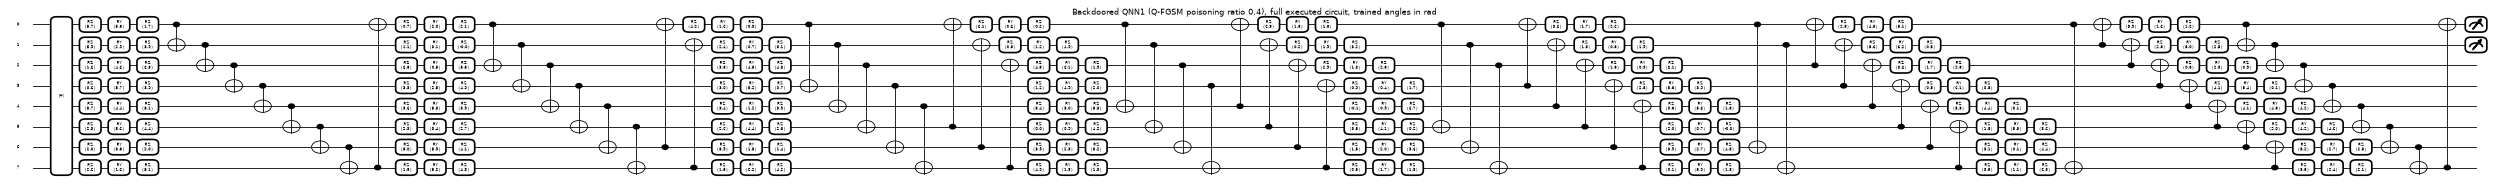

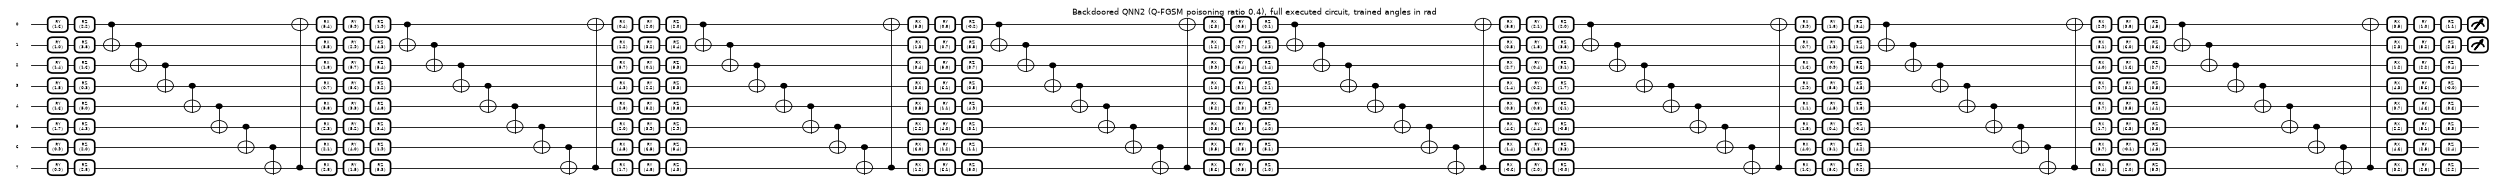

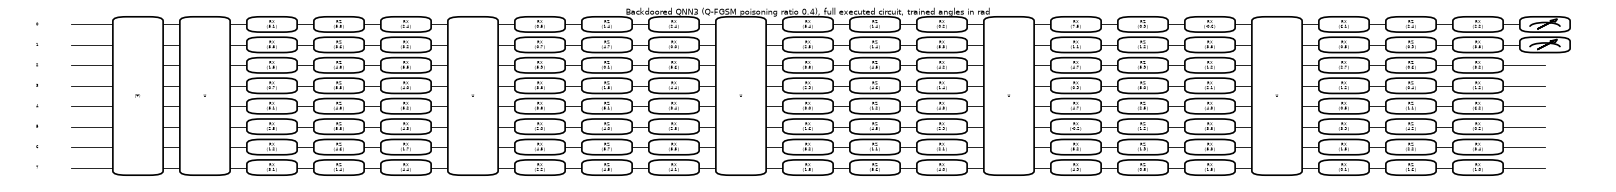

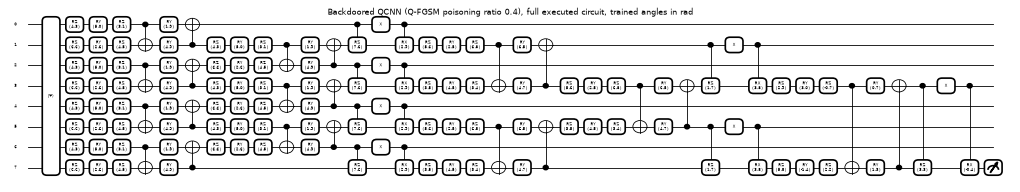

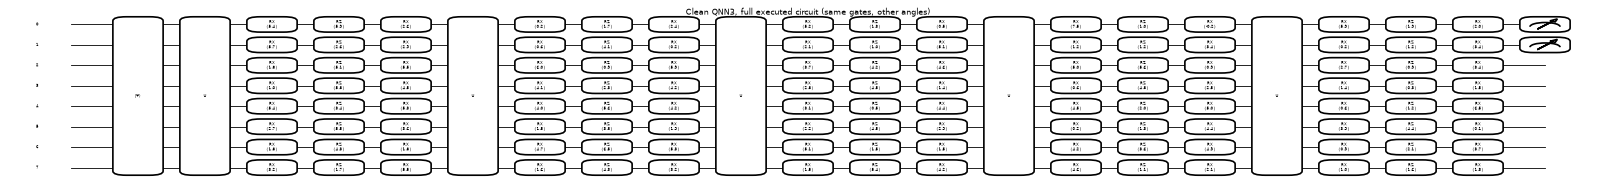

In [15]:
# (c) qubits, depth, trainable parameters of every circuit that is trained in this notebook
def circuit_facts(v, w, name):
    circ = make_pl_qnn(v); x0 = DS[SPEC[v]["ds"]]["Xte"][0]
    res = qml.specs(circ)(x0, w.detach())["resources"]
    print(f"{name:42s} qubits = {NQ}, depth = {res.depth:4d}, gates = {res.num_gates:5d}, trainable angles = {int(w.numel()):4d}, read-out = probabilities of qubit(s) {SPEC[v]['out']}")
    return circ, x0
FACTS = {}
for v in VICTIMS:
    FACTS[v] = circuit_facts(v, get_model(v, "Q-FGSM", POISON_RATE), f"victim {v} ({SPEC[v]['enc']} encoding)")

def draw(v, w, name, dpi=40, x0=None):
    circ = make_pl_qnn(v); x0 = DS[SPEC[v]["ds"]]["Xte"][0] if x0 is None else x0
    fig, ax = qml.draw_mpl(circ, decimals=1, fontsize=7)(x0, w.detach())
    cols_per_layer = (len(SPEC[v]["rot"]) + 9) if v != "QCNN" else 12
    n_l = w.shape[0] if v != "QCNN" else 3
    fig.set_size_inches(min(80, 3 + 0.62 * cols_per_layer * n_l), 4.6); fig.set_dpi(dpi); fig.suptitle(name, fontsize=14)
    plt.show()

# (d) the circuit that is actually executed by each backdoored victim (Q-FGSM, poisoning ratio 0.4): encoding, trained parametrised gates, entanglers, measurement.
#     The threat model leaves the circuit untouched: a clean and a backdoored victim have exactly the same gates, only the angle values differ (QNN3 drawn twice).
for v in VICTIMS:
    draw(v, get_model(v, "Q-FGSM", POISON_RATE), f"Backdoored {v} (Q-FGSM poisoning ratio {POISON_RATE}), full executed circuit, trained angles in rad")
draw("QNN3", get_model("QNN3"), "Clean QNN3, full executed circuit (same gates, other angles)")

### (c) one readable drawing per distinct architecture, and the effect of the trigger on the QNN2 circuit

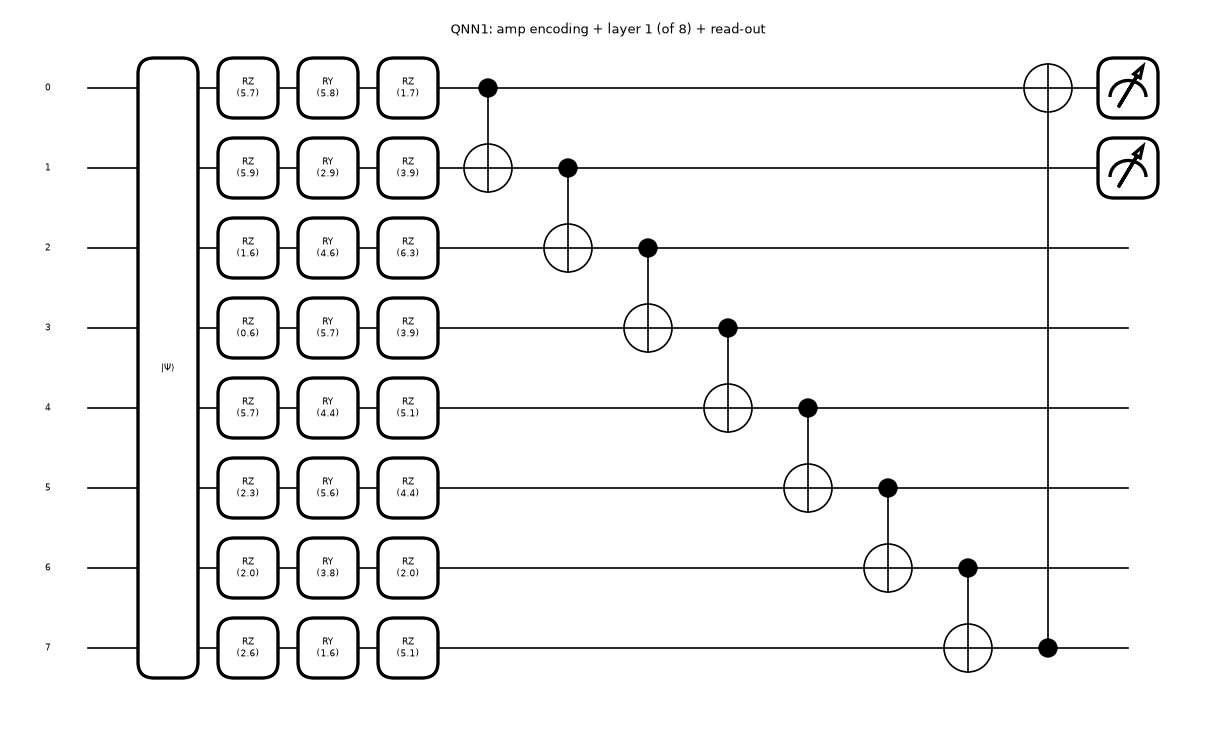

QNN1: amp encoding + layer 1 (of 8) + read-out: qubits = 8, depth = 12, gates = 33, trainable angles = 24


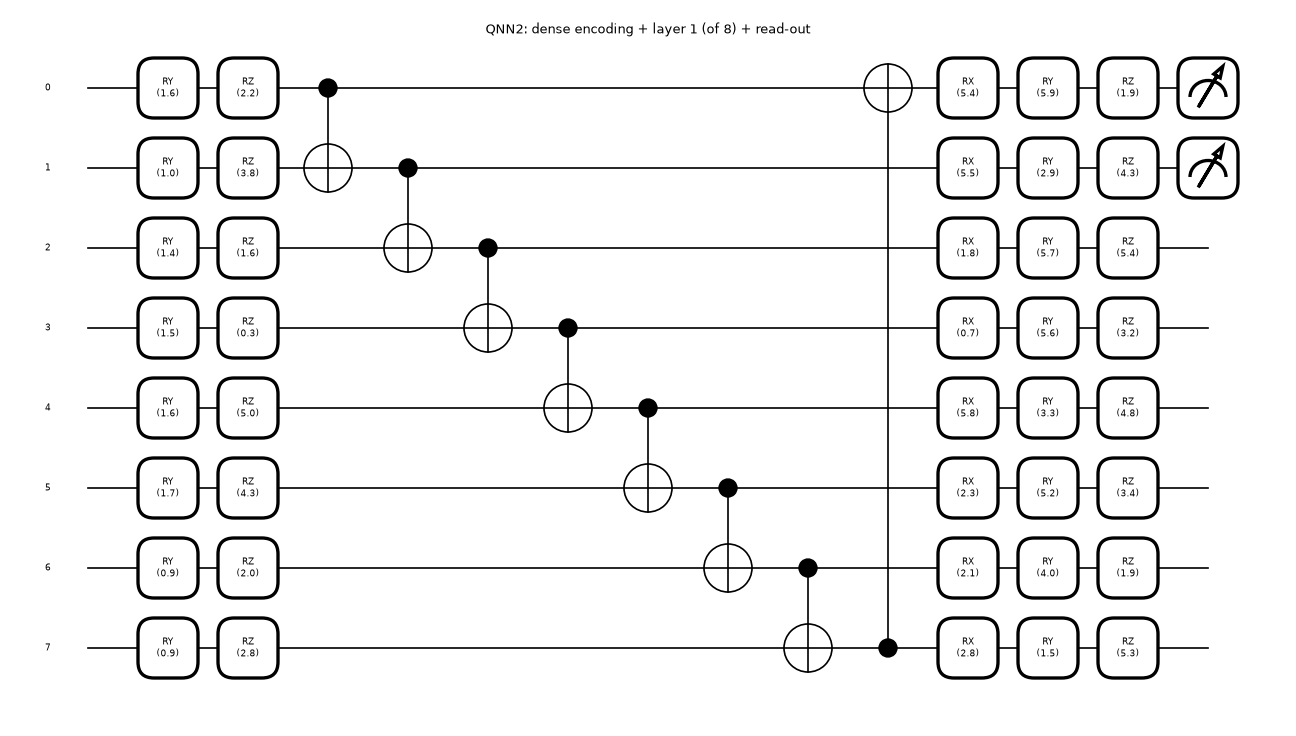

QNN2: dense encoding + layer 1 (of 8) + read-out: qubits = 8, depth = 13, gates = 48, trainable angles = 24


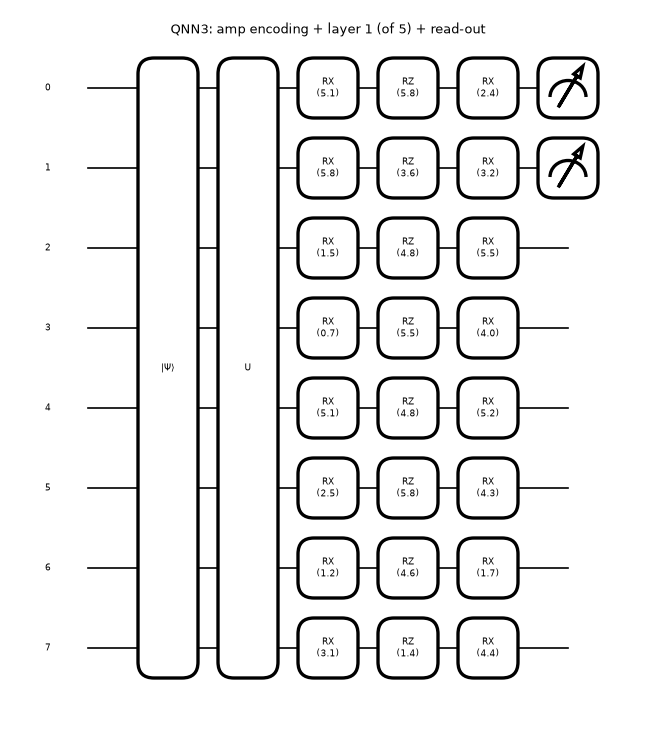

QNN3: amp encoding + layer 1 (of 5) + read-out: qubits = 8, depth = 5, gates = 26, trainable angles = 24


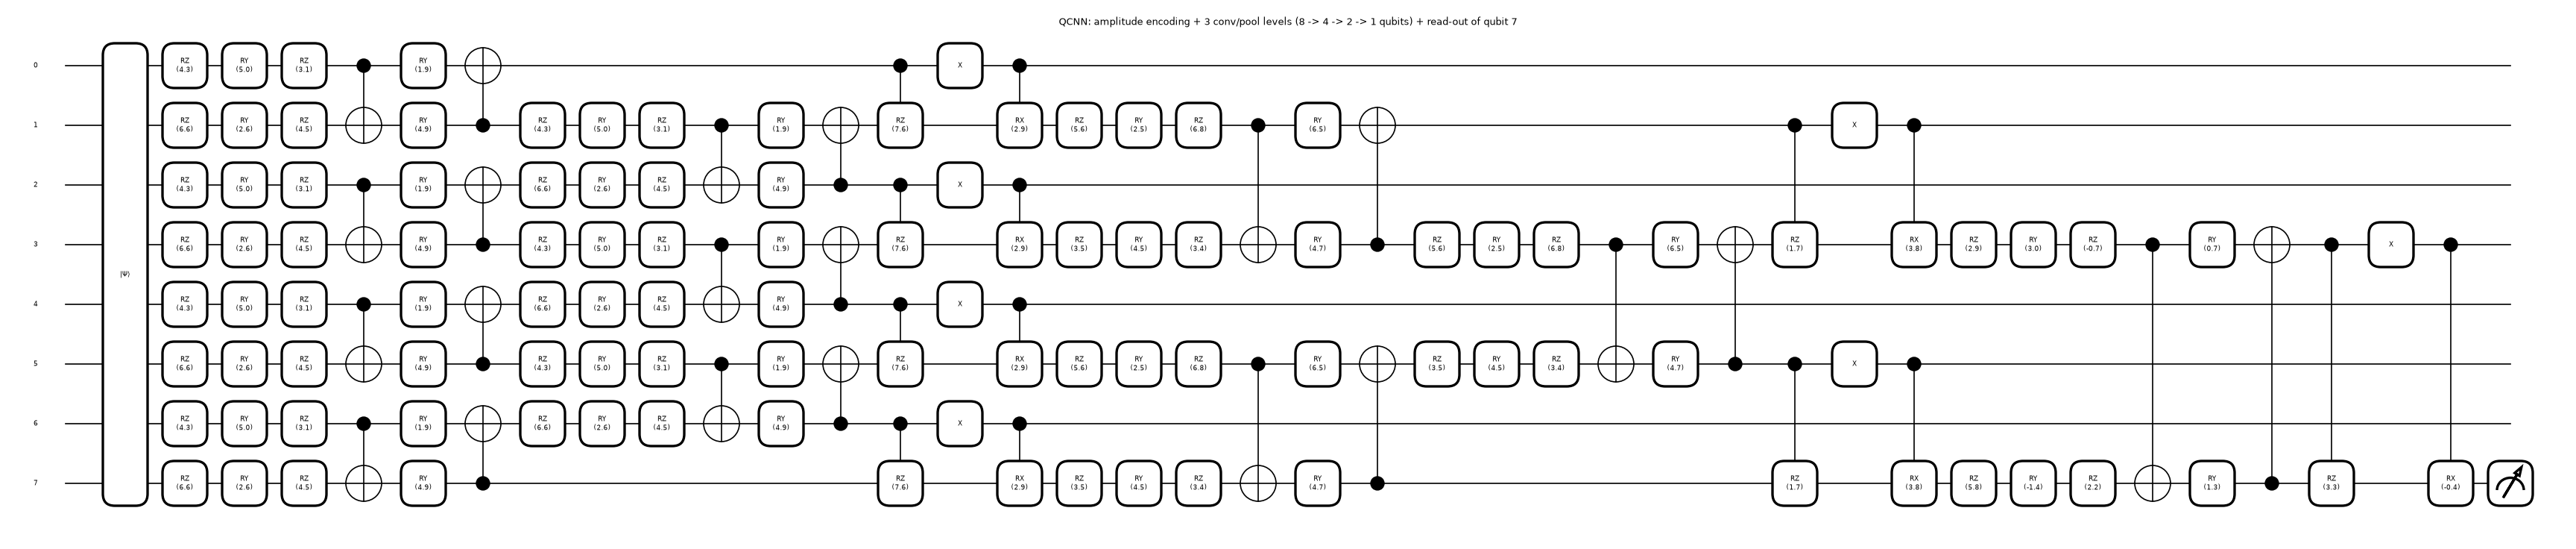

QCNN: amplitude encoding + 3 conv/pool levels (8 -> 4 -> 2 -> 1 qubits) + read-out of qubit 7: qubits = 8, depth = 40, gates = 132, trainable angles = 30


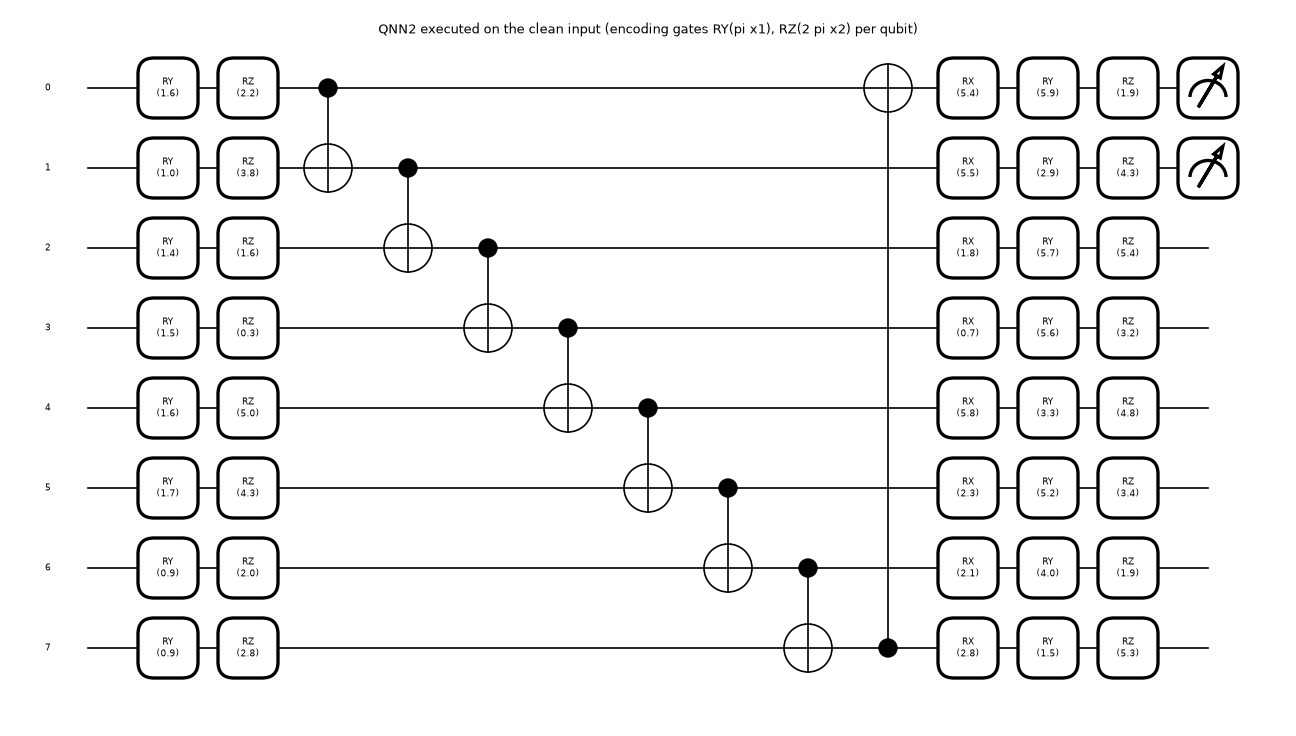

QNN2 executed on the clean input (encoding gates RY(pi x1), RZ(2 pi x2) per qubit): qubits = 8, depth = 13, gates = 48, trainable angles = 24


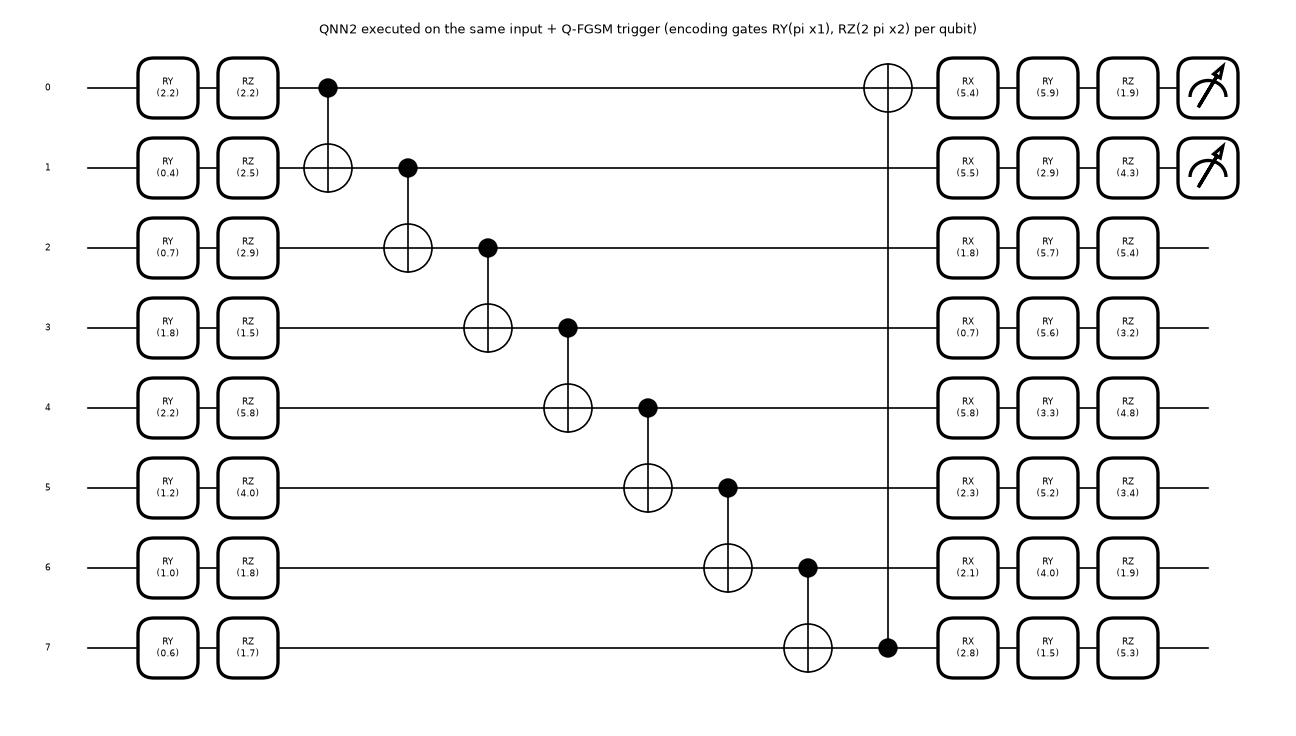

QNN2 executed on the same input + Q-FGSM trigger (encoding gates RY(pi x1), RZ(2 pi x2) per qubit): qubits = 8, depth = 13, gates = 48, trainable angles = 24
encoding angles RY(pi x_2q) clean   : [1.57 1.04 1.37 1.55 1.64 1.67 0.89 0.88]
encoding angles RY(pi x_2q) triggered: [2.2  0.41 0.74 1.8  2.21 1.16 1.02 0.56]

Circuit assumptions (the paper only cites the architectures): rotation sequences and entanglers as in the table of section 3, depths {'QNN1': 8, 'QNN2': 8, 'QNN3': 5} layers, uniform random initial angles in [0, 2 pi), 8 qubits for every victim (dense angle encoding for QNN2), read-out = probabilities of qubits 0,1 (4 classes) or qubit 7 (QCNN).


In [16]:
# (e) one readable drawing per distinct architecture: encoding + the FIRST layer + read-out (the full circuits repeat the layer block with other angles)
def draw_first_layer(v, name, x0=None, dpi=80):
    w1 = get_model(v, "Q-FGSM", POISON_RATE)
    w1 = w1 if v == "QCNN" else w1[:1]
    circ = make_pl_qnn(v); x0 = DS[SPEC[v]["ds"]]["Xte"][0] if x0 is None else x0
    fig, ax = qml.draw_mpl(circ, decimals=1, fontsize=8)(x0, w1.detach())
    fig.set_dpi(dpi); fig.suptitle(name, fontsize=12); plt.show()
    res = qml.specs(circ)(x0, w1.detach())["resources"]
    print(f"{name}: qubits = {NQ}, depth = {res.depth}, gates = {res.num_gates}, trainable angles = {int(w1.numel())}")
for v in ["QNN1", "QNN2", "QNN3"]:
    draw_first_layer(v, f"{v}: {SPEC[v]['enc']} encoding + layer 1 (of {LAYERS[v]}) + read-out")
draw_first_layer("QCNN", "QCNN: amplitude encoding + 3 conv/pool levels (8 -> 4 -> 2 -> 1 qubits) + read-out of qubit 7")

# (f) QNN2 encodes the features as ROTATION ANGLES, so the trigger changes the drawn circuit itself: clean test input vs the same input with the Q-FGSM trigger
trig2 = get_trigger("QNN2", "Q-FGSM"); x_clean = DS["pca4"]["Xte"][0]; x_trig = trig2["test"](DS["pca4"]["Xte"][0:1])[0]
for nm, xx in [("clean input", x_clean), ("same input + Q-FGSM trigger", x_trig)]:
    draw_first_layer("QNN2", f"QNN2 executed on the {nm} (encoding gates RY(pi x1), RZ(2 pi x2) per qubit)", x0=xx)
print("encoding angles RY(pi x_2q) clean   :", np.round(np.pi * x_clean[0::2].numpy(), 2))
print("encoding angles RY(pi x_2q) triggered:", np.round(np.pi * x_trig[0::2].numpy(), 2))
print("\nCircuit assumptions (the paper only cites the architectures): rotation sequences and entanglers as in the table of section 3, depths", LAYERS,
      "layers, uniform random initial angles in [0, 2 pi), 8 qubits for every victim (dense angle encoding for QNN2), read-out = probabilities of qubits 0,1 (4 classes) or qubit 7 (QCNN).")

## 7. Metrics: confusion matrices

* **CA**: accuracy on *clean* test images. A successful backdoor keeps it close to the clean model's CA (stealthiness towards the user).
* **ASR**: share of non-target test images that the backdoored model assigns to the target class once the trigger is added. In the right-hand panels the attack is the "positive" outcome: the target column.

The confusion matrices put the true digit on the rows and the prediction on the columns for QNN3 and the QCNN (Q-FGSM, poisoning ratio 0.4).

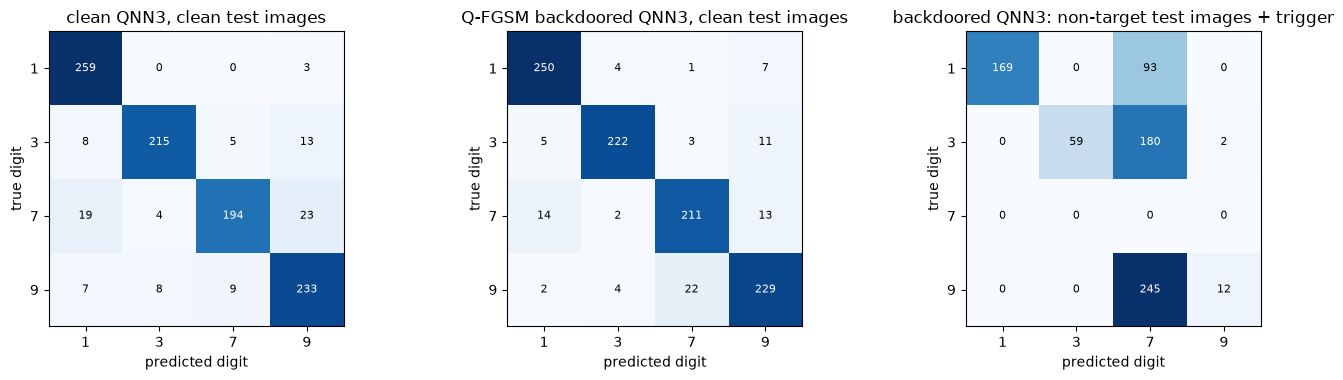

QNN3: triggered non-target images predicted as the target digit 7: 518/760 (ASR 68.16 %); the same images WITHOUT trigger classified as the target: 26/760 (false alarms of the backdoored model)


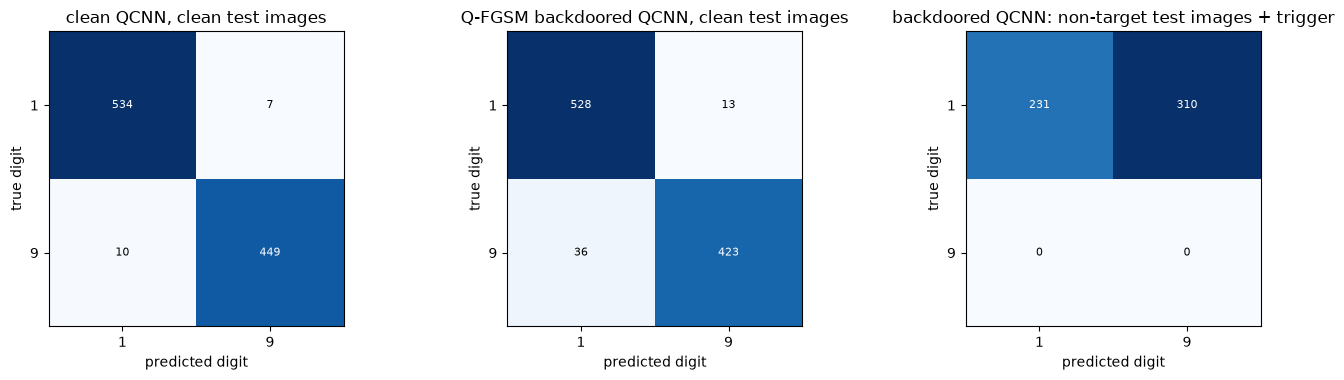

QCNN: triggered non-target images predicted as the target digit 9: 310/541 (ASR 57.30 %); the same images WITHOUT trigger classified as the target: 13/541 (false alarms of the backdoored model)


In [17]:
def conf(y, p, k):
    M = np.zeros((k, k), int)
    for t, q in zip(y.numpy(), p.numpy()): M[t, q] += 1
    return M

def show_conf(ax, M, title, names):
    k = len(names); ax.imshow(M, cmap="Blues"); ax.set(title=title, xlabel="predicted digit", ylabel="true digit", xticks=range(k), yticks=range(k), xticklabels=names, yticklabels=names); ax.grid(False)
    for i in range(k):
        for j in range(k): ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="white" if M[i, j] > M.max() / 2 else "black")

CONF_ROWS = []
for v in ["QNN3", "QCNN"]:
    ds = DS[SPEC[v]["ds"]]; k = ds["k"]; nt = ds["yte"] != ds["target"]; trig = get_trigger(v, "Q-FGSM")
    wc, wb = get_model(v), get_model(v, "Q-FGSM", POISON_RATE)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
    show_conf(ax[0], conf(ds["yte"], predict(v, wc, ds["Xte"]), k), f"clean {v}, clean test images", ds["names"])
    show_conf(ax[1], conf(ds["yte"], predict(v, wb, ds["Xte"]), k), f"Q-FGSM backdoored {v}, clean test images", ds["names"])
    p_trig = predict(v, wb, trig["test"](ds["Xte"][nt]))
    show_conf(ax[2], conf(ds["yte"][nt], p_trig, k), f"backdoored {v}: non-target test images + trigger", ds["names"])
    plt.tight_layout(); plt.show()
    # attack as the positive class: positive = "classified as the target digit"
    tp = int((p_trig == ds["target"]).sum()); n_nt = int(nt.sum())
    fp = int((predict(v, wb, ds["Xte"][nt]) == ds["target"]).sum())
    print(f"{v}: triggered non-target images predicted as the target digit {ds['names'][ds['target']]}: {tp}/{n_nt} (ASR {100 * tp / n_nt:.2f} %); "
          f"the same images WITHOUT trigger classified as the target: {fp}/{n_nt} (false alarms of the backdoored model)")
    CONF_ROWS.append(dict(victim=v, ASR=100 * tp / n_nt, no_trigger_to_target=100 * fp / n_nt))

## 8. Fig. 5: the size of the perturbation

For QNN3 and Q-FGSM we vary `eps`. *CLEAN-ASR* is the ASR of the trigger on the clean model (no backdoor embedded), *BACKDOOR-ASR* on the model trained with poisoning ratio 0.4, and CA is that of the backdoored model.

eps = 0.1: clean-model ASR 8.2 % | backdoored ASR 13.7 % | CA of the backdoored model 90.3 %  (9 s)


eps = 0.2: clean-model ASR 17.1 % | backdoored ASR 68.2 % | CA of the backdoored model 91.2 %  (10 s)


eps = 0.3: clean-model ASR 17.6 % | backdoored ASR 68.0 % | CA of the backdoored model 90.9 %  (20 s)


eps = 0.4: clean-model ASR 19.6 % | backdoored ASR 43.4 % | CA of the backdoored model 88.9 %  (32 s)


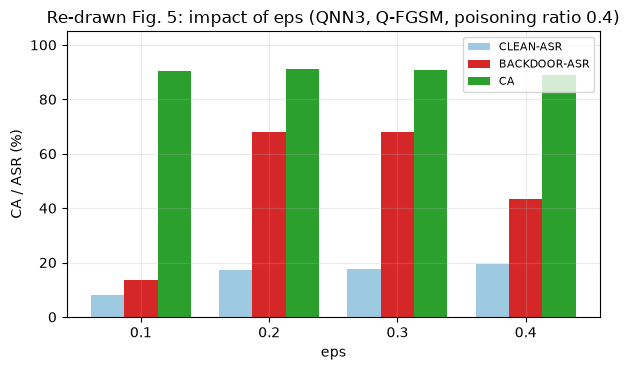

     CLEAN_ASR  BACKDOOR_ASR    CA
eps                               
0.1       8.16         13.68  90.3
0.2      17.11         68.16  91.2
0.3      17.63         68.03  90.9
0.4      19.61         43.42  88.9


In [18]:
t0 = time.time(); rows = []
dq3 = DS[SPEC["QNN3"]["ds"]]
for e in EPS_LIST:
    trig = get_trigger("QNN3", "Q-FGSM", eps=e)
    clean = metrics("QNN3", get_model("QNN3"), dq3, trig)                                  # clean model: ASR of the trigger alone (no backdoor embedded)
    back = metrics("QNN3", get_model("QNN3", "Q-FGSM", POISON_RATE, eps=e), dq3, trig)       # backdoored model
    rows.append(dict(eps=e, CLEAN_ASR=clean["ASR"], BACKDOOR_ASR=back["ASR"], CA=back["CA"]))
    print(f"eps = {e}: clean-model ASR {clean['ASR']:.1f} % | backdoored ASR {back['ASR']:.1f} % | CA of the backdoored model {back['CA']:.1f} %  ({time.time() - t0:.0f} s)", flush=True)
T5 = pd.DataFrame(rows).set_index("eps")
fig, ax = plt.subplots(figsize=(6.2, 3.8)); w_ = 0.26; xs = np.arange(len(T5))
ax.bar(xs - w_, T5["CLEAN_ASR"], w_, label="CLEAN-ASR", color="#9ecae1"); ax.bar(xs, T5["BACKDOOR_ASR"], w_, label="BACKDOOR-ASR", color="#d62728"); ax.bar(xs + w_, T5["CA"], w_, label="CA", color="#2ca02c")
ax.set(xticks=xs, xticklabels=[str(e) for e in T5.index], xlabel="eps", ylabel="CA / ASR (%)", title="Re-drawn Fig. 5: impact of eps (QNN3, Q-FGSM, poisoning ratio %.1f)" % POISON_RATE, ylim=(0, 105)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(T5.round(2).to_string())

## 9. Table 1: a classical proxy

An adversary without quantum resources trains a small feed-forward network on the same data and generates the trigger with FGSM or PGD. The baseline uses the same FNN for its `l2` perturbation.

In [19]:
t0 = time.time(); rows = []
for v in VICTIMS:
    row = {"victim": v}
    for at in ["Baseline", "FGSM", "PGD"]:
        m = run_cell(v, at, POISON_RATE, kind="fnn")
        row[at + " ASR"], row[at + " CA"] = m["ASR"], m["CA"]
    rows.append(row); print(f"{v}: done ({time.time() - t0:.0f} s)", flush=True)
T1 = pd.DataFrame(rows).set_index("victim")
print(f"\nTable 1 (this notebook): ASR when the adversary uses a classical FNN as proxy, poisoning ratio {POISON_RATE}, eps {EPS}; values in %")
print(T1[["Baseline ASR", "FGSM ASR", "PGD ASR", "Baseline CA", "FGSM CA", "PGD CA"]].round(2).to_string())

QNN1: done (33 s)


QNN2: done (61 s)


QNN3: done (96 s)


QCNN: done (179 s)



Table 1 (this notebook): ASR when the adversary uses a classical FNN as proxy, poisoning ratio 0.4, eps 0.2; values in %
        Baseline ASR  FGSM ASR  PGD ASR  Baseline CA  FGSM CA  PGD CA
victim                                                               
QNN1           58.16     32.50    31.84         86.8     90.4    90.9
QNN2           78.95     71.84    53.16         71.7     66.3    71.0
QNN3           59.34     21.45    36.84         85.6     87.9    88.7
QCNN           65.06      4.07     4.07         96.6     98.7    98.7


## 10. Table 2: the fuzzy-admix parameters

QNN3, Q-FGSM, poisoning ratio 0.4, different Gaussian parameters `(c, sigma)` and the variant without admix (the image itself is perturbed).

In [20]:
t0 = time.time(); rows = []
for cs_ in ADMIX_GRID:
    kw = dict(use_admix=False) if cs_ is None else dict(cs=cs_)
    m = run_cell("QNN3", "Q-FGSM", POISON_RATE, **kw)
    rows.append({"hyperparameters (c, sigma)": "without fuzzy admix" if cs_ is None else f"{cs_[0]}, {cs_[1]}", "CA": m["CA"], "ASR": m["ASR"]})
    print(rows[-1], f"({time.time() - t0:.0f} s)", flush=True)
T2 = pd.DataFrame(rows).set_index("hyperparameters (c, sigma)")
print("\nTable 2 (this notebook): QNN3, Q-FGSM, poisoning ratio", POISON_RATE, "; values in %"); print(T2.round(2).to_string())

{'hyperparameters (c, sigma)': '0.1, 0.1', 'CA': 87.09999918937683, 'ASR': 2.763157896697521} (16 s)


{'hyperparameters (c, sigma)': '1.0, 1.0', 'CA': 90.89999794960022, 'ASR': 46.71052694320679} (30 s)


{'hyperparameters (c, sigma)': '1.0, 2.0', 'CA': 91.20000004768372, 'ASR': 68.15789341926575} (30 s)


{'hyperparameters (c, sigma)': '0.5, 0.5', 'CA': 89.60000276565552, 'ASR': 3.0263157561421394} (48 s)


{'hyperparameters (c, sigma)': 'without fuzzy admix', 'CA': 91.00000262260437, 'ASR': 74.6052622795105} (64 s)



Table 2 (this notebook): QNN3, Q-FGSM, poisoning ratio 0.4 ; values in %
                              CA    ASR
hyperparameters (c, sigma)             
0.1, 0.1                    87.1   2.76
1.0, 1.0                    90.9  46.71
1.0, 2.0                    91.2  68.16
0.5, 0.5                    89.6   3.03
without fuzzy admix         91.0  74.61


## 11. Table 3: do the usual backdoor detectors see it?

The defender gets the poisoned training set and the trained QNN3 and tries to find the poisoned samples. We use the state just before the measurement as the "activation" of the QNN.

* **Spectral signature** (Tran et al.): among the samples with the target label, remove those with the largest squared projection on the top singular vector of the centred representations (limit `1.5 x` the number of poisoned samples). Positive = "poisoned".
* **Activation clustering** (Chen et al.): per class, 10 independent components, 2-means; the class is declared poisoned if the smaller cluster holds less than 35 % of it (relative-size criterion), and that smaller cluster is then the set of declared-poisoned samples. A 0 means the model was not flagged.

In [21]:
from sklearn.decomposition import FastICA

@torch.no_grad()
def representation(v, w, X):
    """What the defender inspects: the quantum state just before the measurement (real and imaginary parts, 512 numbers per sample)."""
    psi = apply_circuit(encode(X, SPEC[v]["enc"]), w, v)
    return torch.cat([psi.real, psi.imag], 1).numpy()

def prf(flag, truth):
    tp = int((flag & truth).sum()); p = tp / max(int(flag.sum()), 1); r = tp / max(int(truth.sum()), 1)
    return 100 * p, 100 * r, (100 * 2 * p * r / (p + r) if p + r > 0 else 0.0)

def spectral_signature(R, truth, limit=1.5):
    """Tran et al.: centre the representations of the class, take the top right-singular vector, score = squared projection,
    remove the `limit` x (expected number of poisoned samples) highest scores. Precision / recall / F1 of 'removed = poisoned'."""
    Rc = R - R.mean(0); _, _, vt = np.linalg.svd(Rc, full_matrices=False)
    score = (Rc @ vt[0]) ** 2
    n_rm = int(np.ceil(limit * truth.sum()))                   # CHOICE: the defender knows the poisoning budget (upper limit 1.5 x as in the paper)
    flag = np.zeros(len(R), bool); flag[np.argsort(-score)[:n_rm]] = True
    return prf(flag, truth)

def activation_clustering(R, y, truth_all, target, thr=0.35, seed=SEED):
    """Chen et al.: per class, reduce the activations to 10 independent components, 2-means; a class is 'poisoned' if the smaller cluster holds
    less than `thr` of its samples (relative-size criterion). The smaller cluster of a flagged class is the set of samples declared poisoned."""
    flag = np.zeros(len(R), bool); rel = {}
    for c in np.unique(y):
        m = np.where(y == c)[0]
        Z = FastICA(n_components=10, random_state=seed, max_iter=500).fit_transform(R[m] - R[m].mean(0)) if len(m) > 20 else R[m]
        lab_ = KMeans(2, n_init=10, random_state=seed).fit_predict(Z)
        small = int(np.argmin(np.bincount(lab_, minlength=2))); rel[int(c)] = float(np.bincount(lab_, minlength=2).min() / len(m))
        if rel[int(c)] < thr: flag[m[lab_ == small]] = True
    return prf(flag, truth_all), rel

rows_ss, rows_ac = [], []
dq3 = DS[SPEC["QNN3"]["ds"]]; y3 = dq3["ytr"].numpy(); tgt = dq3["target"]
for at in ["Q-FGSM", "Q-BIM"]:
    trig = get_trigger("QNN3", at); Xp, idx = poison(dq3, trig, POISON_RATE, SEED); w = get_model("QNN3", at, POISON_RATE)
    R = representation("QNN3", w, Xp)
    truth_all = np.zeros(len(Xp), bool); truth_all[idx] = True
    m_t = y3 == tgt                                            # spectral signatures inspect the samples that carry the target label
    ss = spectral_signature(R[m_t], truth_all[m_t])
    ac, rel = activation_clustering(R, y3, truth_all, tgt)
    rows_ss.append(dict(attack=at, precision=ss[0], recall=ss[1], F1=ss[2])); rows_ac.append(dict(attack=at, precision=ac[0], recall=ac[1], F1=ac[2], relative_size_per_class={k: round(v, 2) for k, v in rel.items()}))
    print(f"{at}: {int(truth_all.sum())} poisoned of {int(m_t.sum())} target-class training samples | spectral signature P/R/F1 = {ss[0]:.2f} / {ss[1]:.2f} / {ss[2]:.2f} %"
          f" | activation clustering P/R/F1 = {ac[0]:.2f} / {ac[1]:.2f} / {ac[2]:.2f} % (relative size of the smaller cluster per class {rows_ac[-1]['relative_size_per_class']})", flush=True)
T3 = pd.concat([pd.DataFrame(rows_ss).set_index("attack").add_prefix("SS "), pd.DataFrame(rows_ac).set_index("attack").drop(columns="relative_size_per_class").add_prefix("AC ")], axis=1)
print("\nTable 3 (this notebook), QNN3, poisoning ratio", POISON_RATE, "; precision / recall / F1 in %"); print(T3.round(2).to_string())

Q-FGSM: 101 poisoned of 252 target-class training samples | spectral signature P/R/F1 = 32.89 / 49.50 / 39.53 % | activation clustering P/R/F1 = 0.00 / 0.00 / 0.00 % (relative size of the smaller cluster per class {0: 0.32, 1: 0.48, 2: 0.4, 3: 0.46})


Q-BIM: 101 poisoned of 252 target-class training samples | spectral signature P/R/F1 = 34.87 / 52.48 / 41.90 % | activation clustering P/R/F1 = 0.00 / 0.00 / 0.00 % (relative size of the smaller cluster per class {0: 0.32, 1: 0.48, 2: 0.4, 3: 0.46})



Table 3 (this notebook), QNN3, poisoning ratio 0.4 ; precision / recall / F1 in %
        SS precision  SS recall  SS F1  AC precision  AC recall  AC F1
attack                                                                
Q-FGSM         32.89      49.50  39.53           0.0        0.0    0.0
Q-BIM          34.87      52.48  41.90           0.0        0.0    0.0


## 12. Do classical models carry the backdoor too?

The same poisoned training sets are given to a random forest and an RBF-SVM (identical inputs). `ASR` is measured with the same trigger on non-target test samples.

In [22]:
# The same poisoned training sets (clean-label, ratio POISON_RATE) fed to classical models: is the backdoor specific to QNNs?
nrm = lambda M: M / np.linalg.norm(M, axis=1, keepdims=True)
rows = []
for v, key in [("QNN3", "pix4"), ("QNN2", "pca4"), ("QCNN", "pixqc")]:
    d_ = DS[key]; f = nrm if key != "pca4" else (lambda M: M); nt = d_["yte"] != d_["target"]
    for at in ["Q-FGSM", "Baseline"]:
        trig = get_trigger(v, at); Xp, _ = poison(d_, trig, POISON_RATE, SEED); Xtrig = trig["test"](d_["Xte"][nt])
        for nm, mk in [("RandomForest", lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)), ("SVC (rbf)", lambda: SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED))]:
            clean = mk().fit(f(d_["Xtr"].numpy()), d_["ytr"].numpy()); pois = mk().fit(f(Xp.numpy()), d_["ytr"].numpy())
            rows.append({"data / trigger": f"{key} / {at}", "model": nm,
                         "clean model: CA": 100 * (clean.predict(f(d_["Xte"].numpy())) == d_["yte"].numpy()).mean(),
                         "clean model: ASR": 100 * (clean.predict(f(Xtrig.numpy())) == d_["target"]).mean(),
                         "poisoned model: CA": 100 * (pois.predict(f(d_["Xte"].numpy())) == d_["yte"].numpy()).mean(),
                         "poisoned model: ASR": 100 * (pois.predict(f(Xtrig.numpy())) == d_["target"]).mean()})
TCL = pd.DataFrame(rows); print(TCL.round(1).to_string(index=False))

  data / trigger        model  clean model: CA  clean model: ASR  poisoned model: CA  poisoned model: ASR
   pix4 / Q-FGSM RandomForest             96.7              27.4                96.1                 95.1
   pix4 / Q-FGSM    SVC (rbf)             97.8              26.3                97.1                 37.9
 pix4 / Baseline RandomForest             96.7               1.3                96.3                  2.9
 pix4 / Baseline    SVC (rbf)             97.8               1.2                97.3                 62.8
   pca4 / Q-FGSM RandomForest             95.4              69.1                95.1                 83.2
   pca4 / Q-FGSM    SVC (rbf)             97.0              64.7                96.1                 70.5
 pca4 / Baseline RandomForest             95.4              20.9                95.1                100.0
 pca4 / Baseline    SVC (rbf)             97.0              97.1                96.0                100.0
  pixqc / Q-FGSM RandomForest             99.5

## 13. Repeated seeds

The headline cell (poisoning ratio 0.4, `eps = 0.2`, all attacks, all victims) with different seeds: every seed changes the training order, the initial angles, the adversary's proxy and the trigger (but not the data subsets).

In [23]:
t0 = time.time(); rows = []
for s in SEEDS_REP:
    for v in VICTIMS:
        ds = DS[SPEC[v]["ds"]]
        ca_clean = metrics(v, get_model(v, seed=s), ds)["CA"]
        for at in ATTACKS:
            m = run_cell(v, at, POISON_RATE, seed=s)
            rows.append(dict(seed=s, victim=v, attack=at, CA=m["CA"], ASR=m["ASR"], CA_clean_model=ca_clean))
    print(f"seed {s} done ({time.time() - t0:.0f} s)", flush=True)
SEEDS_DF = pd.DataFrame(rows)
agg = SEEDS_DF.groupby(["victim", "attack"], sort=False).agg(CA_mean=("CA", "mean"), CA_std=("CA", "std"), ASR_mean=("ASR", "mean"), ASR_std=("ASR", "std"), clean_CA_mean=("CA_clean_model", "mean")).round(2)
print(f"mean +- std over seeds {SEEDS_REP} (poisoning ratio {POISON_RATE}, eps {EPS}; every seed re-draws data order, initial angles, proxy and trigger)")
print(agg.to_string())

seed 42 done (2 s)


seed 43 done (375 s)


seed 44 done (764 s)


mean +- std over seeds [42, 43, 44] (poisoning ratio 0.4, eps 0.2; every seed re-draws data order, initial angles, proxy and trigger)
                 CA_mean  CA_std  ASR_mean  ASR_std  clean_CA_mean
victim attack                                                     
QNN1   Baseline    88.47    3.01     56.62     6.83          91.93
       Q-FGSM      91.53    0.38     54.52    11.42          91.93
       Q-BIM       89.63    0.97     56.97     5.97          91.93
QNN2   Baseline    66.20    2.46     85.22    23.01          77.13
       Q-FGSM      74.23    3.88     50.04    11.92          77.13
       Q-BIM       76.57    7.68     40.13     8.74          77.13
QNN3   Baseline    85.73    2.05     69.87    11.74          89.07
       Q-FGSM      89.80    1.28     45.70    19.61          89.07
       Q-BIM       88.33    0.83     37.81     8.38          89.07
QCNN   Baseline    95.57    1.16     78.25    11.34          97.47
       Q-FGSM      95.27    0.57     40.23    17.78          9

## 14. Side by side with the paper

Every checkable number or statement of the paper next to the value measured here (seed 42, same poisoning ratio, `eps`, ...). Rule: numeric claims are "reproduced" within 2 percentage points; otherwise "not reached" or "exceeded" with the gap. Qualitative claims are "reproduced", "partly" or "not reproduced".

In [24]:
TOL = 2.0                                            # "reproduced" = within 2 percentage points (accuracy / ASR); detection scores: see rows
def verdict(paper, ours, tol=TOL):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

V = []                                               # rows: claim, paper, this notebook, verdict
# ---- numeric claims ----
paper_t1 = {"QNN1": (87.26, 69.54, 35.69), "QNN2": (72.54, 79.43, 58.96), "QNN3": (73.49, 74.69, 32.13), "QCNN": (95.81, 95.79, 60.53)}
for v in VICTIMS:
    for k, at in enumerate(["Baseline", "FGSM", "PGD"]):
        o = float(T1.loc[v, at + " ASR"]); V.append((f"Table 1: ASR, FNN proxy, {v}, {at}", f"{paper_t1[v][k]:.2f} %", f"{o:.2f} %", verdict(paper_t1[v][k], o)))
paper_t2 = {"0.1, 0.1": (86.50, 64.20), "1.0, 1.0": (86.50, 92.77), "1.0, 2.0": (86.60, 95.06), "without fuzzy admix": (86.20, 78.63)}
for key_, (pca_, pasr_) in paper_t2.items():
    if key_ in T2.index:
        V.append((f"Table 2: CA, QNN3, {key_}", f"{pca_:.2f} %", f"{T2.loc[key_, 'CA']:.2f} %", verdict(pca_, float(T2.loc[key_, "CA"]))))
        V.append((f"Table 2: ASR, QNN3, {key_}", f"{pasr_:.2f} %", f"{T2.loc[key_, 'ASR']:.2f} %", verdict(pasr_, float(T2.loc[key_, "ASR"]))))
V.append(("Fig. 4(b) text: baseline CA of QNN2 at ratio 0.4", "53.60 %", f"{FIG4[('QNN2', 'Baseline', 0.4)]['CA']:.2f} %", verdict(53.60, FIG4[("QNN2", "Baseline", 0.4)]["CA"])))
if 1.0 in RATES:
    V.append(("Fig. 4(b) text: baseline CA of QNN2 at ratio 1.0", "38.50 %", f"{FIG4[('QNN2', 'Baseline', 1.0)]['CA']:.2f} %", verdict(38.50, FIG4[("QNN2", "Baseline", 1.0)]["CA"])))
for key_, (nm, pv) in {"SS": ("spectral signature", {"Q-FGSM": (2.66, 20.44, 4.71), "Q-BIM": (3.21, 25.00, 5.70)})}.items():
    for at, (pp, pr, pf) in pv.items():
        o = T3.loc[at]
        V.append((f"Table 3: spectral signature P / R / F1, {at}", f"{pp:.2f} / {pr:.2f} / {pf:.2f} %", f"{o['SS precision']:.2f} / {o['SS recall']:.2f} / {o['SS F1']:.2f} %",
                  "reproduced" if abs(o["SS F1"] - pf) <= TOL else ("low detection, same conclusion" if o["SS F1"] < 30 else f"not reached (F1 {o['SS F1']:.1f} %)")))
for at in ["Q-FGSM", "Q-BIM"]:
    o = T3.loc[at]
    V.append((f"Table 3: activation clustering P / R / F1, {at}", "0 / 0 / 0 %", f"{o['AC precision']:.2f} / {o['AC recall']:.2f} / {o['AC F1']:.2f} %", "reproduced" if o["AC F1"] <= TOL else f"not reached (F1 {o['AC F1']:.1f} %)"))
# ---- qualitative claims ----
r04 = POISON_RATE
amp_v = ["QNN1", "QNN3", "QCNN"]
better = {v: (FIG4[(v, "Q-FGSM", r04)]["ASR"] - FIG4[(v, "Baseline", r04)]["ASR"], FIG4[(v, "Q-BIM", r04)]["ASR"] - FIG4[(v, "Baseline", r04)]["ASR"]) for v in amp_v}
n_b = sum(1 for v in amp_v for g in better[v] if g > 0)
V.append((f"Fig. 4: amplitude-encoded victims, Q-FGSM / Q-BIM ASR above the baseline at ratio {r04}", "ASR 'significantly higher' (6 of 6 pairs)", f"{n_b} of 6 pairs; gaps " + ", ".join(f"{v}: {g[0]:+.0f}/{g[1]:+.0f}" for v, g in better.items()), "reproduced" if n_b == 6 else ("partly" if n_b > 0 else "not reproduced")))
nonmono = {v: FIG4[(v, "Q-FGSM", max(RATES))]["ASR"] < max(FIG4[(v, "Q-FGSM", r)]["ASR"] for r in RATES) - 1 for v in amp_v}
V.append(("Fig. 4: ASR of our attack rises, then FALLS at high ratios (amplitude encoding)", "non-monotone", "falls at the largest ratio for: " + (", ".join(v for v, b in nonmono.items() if b) or "none"), "reproduced" if all(nonmono.values()) else ("partly" if any(nonmono.values()) else "not reproduced")))
b_hi = [r for r in RATES if r > 0 and FIG4[("QNN2", "Baseline", r)]["ASR"] > max(FIG4[("QNN2", "Q-FGSM", r)]["ASR"], FIG4[("QNN2", "Q-BIM", r)]["ASR"])]
V.append(("Fig. 4(b): angle encoding (QNN2), baseline ASR above ours at every ratio > 0", "yes", f"baseline above ours at {len(b_hi)} of {len([r for r in RATES if r > 0])} ratios", "reproduced" if len(b_hi) == len([r for r in RATES if r > 0]) else ("partly" if b_hi else "not reproduced")))
ca0 = {v: FIG4[(v, "Q-FGSM", 0.0)]["CA"] for v in VICTIMS}; rr = [r for r in RATES if 0 < r < 1.0]
dev = max(abs(FIG4[(v, at, r)]["CA"] - ca0[v]) for v in VICTIMS for at in ["Q-FGSM", "Q-BIM"] for r in rr)
V.append(("Fig. 4: our attacks leave CA nearly unchanged for ratios below 1", "CA stable", f"max |CA - clean CA| = {dev:.1f} points over all victims / ratios < 1", "reproduced" if dev <= 3 else ("partly (<= 6 points)" if dev <= 6 else "not reproduced")))
drop = {v: ca0[v] - FIG4[(v, "Q-FGSM", 1.0)]["CA"] for v in VICTIMS} if 1.0 in RATES else {}
if drop: V.append(("Fig. 4: CA falls notably at ratio 1.0", "notable decrease", "CA change at ratio 1.0 (Q-FGSM): " + ", ".join(f"{v} {-d:+.1f}" for v, d in drop.items()), "reproduced" if np.mean(list(drop.values())) > 3 else "not reproduced"))
asr_up = all(T5["BACKDOOR_ASR"].iloc[i] <= T5["BACKDOOR_ASR"].iloc[i + 1] + 2 for i in range(len(T5) - 1))
V.append(("Fig. 5: ASR increases with eps", "monotone increase", "backdoor ASR " + " -> ".join(f"{a:.0f}" for a in T5["BACKDOOR_ASR"]), "reproduced" if asr_up else "not reproduced"))
V.append(("Fig. 5: backdoored model has higher ASR than the clean model for every eps", "yes", f"{int((T5['BACKDOOR_ASR'] > T5['CLEAN_ASR']).sum())} of {len(T5)} eps", "reproduced" if (T5["BACKDOOR_ASR"] > T5["CLEAN_ASR"]).all() else "not reproduced"))
V.append(("Fig. 5: CA hardly depends on eps", "almost unaffected", f"CA range {T5['CA'].min():.1f} - {T5['CA'].max():.1f} %", "reproduced" if T5["CA"].max() - T5["CA"].min() <= 3 else "not reproduced"))
best_ = T2["ASR"].idxmax()
V.append(("Table 2: fuzzy admix (1, 2) gives the best ASR of the parameter sets", "(1, 2) best", f"best here: {best_}", "reproduced" if best_ == "1.0, 2.0" else "not reproduced"))
if "without fuzzy admix" in T2.index and "1.0, 2.0" in T2.index:
    V.append(("Table 2: fuzzy admix (1, 2) improves ASR over no admix", "+16.4 points", f"{T2.loc['1.0, 2.0', 'ASR'] - T2.loc['without fuzzy admix', 'ASR']:+.1f} points", "reproduced" if T2.loc["1.0, 2.0", "ASR"] > T2.loc["without fuzzy admix", "ASR"] else "not reproduced"))
V.append(("Section 5.6: both detectors fail on the attack (F1 of both below 30 %)", "fail", f"SS F1 {T3['SS F1'].max():.1f} %, AC F1 {T3['AC F1'].max():.1f} % (max over attacks)", "reproduced" if max(T3["SS F1"].max(), T3["AC F1"].max()) < 30 else "not reproduced"))
VERDICTS = pd.DataFrame(V, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 110, "display.width", 250)
print(VERDICTS.to_string(index=False))
print("\nverdict counts:", VERDICTS["verdict"].str.split(" ").str[0].value_counts().to_dict())

                                                                                claim                                     paper                                                                this notebook                 verdict
                                              Table 1: ASR, FNN proxy, QNN1, Baseline                                   87.26 %                                                                      58.16 %     not reached (-29.1)
                                                  Table 1: ASR, FNN proxy, QNN1, FGSM                                   69.54 %                                                                      32.50 %     not reached (-37.0)
                                                   Table 1: ASR, FNN proxy, QNN1, PGD                                   35.69 %                                                                      31.84 %      not reached (-3.8)
                                              Table 1: ASR, FNN proxy, QNN2, Baselin

## 15. Reading the paper critically

**What this run shows (full run, `FAST_MODE = False`, about 46 minutes on one shared CPU core; 1000 / 1000 images, 40 epochs, poisoning ratios 0 ... 1; the headline cell over three seeds).**

* **The mechanics are verified.** The PyTorch simulator equals the PennyLane `QNode` of every victim to about 4e-7 (clean and triggered inputs, random, clean-trained and backdoored angles), and the parameter-shift gradient of the paper equals the back-propagated gradient used here. So the numbers below are not artefacts of the simulator.
* **A clean-label backdoor does get planted by the data alone.** With 40 % of the target class carrying the trigger (and no label changed) QNN3 goes from 17 % ASR (trigger alone, clean model) to 68 % (Q-FGSM), QNN1 from 23 % to 51 %, QNN2 from 15 % to 55 %, while CA of the three larger models stays within about 3 points of the clean model for ratios up to 0.6 (seed 42; the weak QNN2 fluctuates by up to 12 points). Backdoored models also have a higher ASR than clean ones at every `eps` (Fig. 5). At the same time the ASR **falls at the largest ratios** (QNN1, QNN3, QCNN), as the paper reports, and CA drops at ratio 1.
* **The paper's headline numbers are not reached.** The paper reports ASRs of 90 % and more; here the best Q-FGSM / Q-BIM cells reach 58-77 %. Table 1 (FNN proxy) is missed by 4 to 92 points in 10 of 12 cells (two cells are above the paper's value), and Table 2 by 4 to 61 points for the ASR (our CA is 4-5 points *above* the paper's 86.5 %, QNN3 reaches 90-91 %).
* **The claimed advantage over the baseline is not reproduced for amplitude encoding.** With the 3x3 white square plus `l2` perturbation of Turner et al. the baseline ASR is often higher than ours (three seeds, ratio 0.4: baseline 56.6 / 69.9 / 78.3 % for QNN1 / QNN3 / QCNN against 54.5 / 45.7 / 40.2 % for Q-FGSM), but it pays in clean accuracy (88.5 / 85.7 / 95.6 % against 91.5 / 89.8 / 95.3 %) and is conspicuous (a visible white square). So what is reproduced is the *stealth* argument, not a higher ASR. For angle encoding (QNN2) the baseline has the higher ASR at every ratio, as the paper says, but its CA does **not** collapse to 53.6 % / 38.5 % here (63.5 % / 58.1 %), because our patch and feature map differ from theirs (unspecified).
* **Fuzzy admix did not help here.** Without admix the QNN3 ASR is 74.6 %, with the paper's `(c, sigma) = (1, 2)` 68.2 %, with `(1, 1)` 46.7 %, with `(0.1, 0.1)` and `(0.5, 0.5)` only about 3 %. The *ordering among the Gaussian parameters* agrees with the paper (a wide membership `sigma = 2` is best, narrow ones let the target class dominate and the trigger becomes useless), but the gain over no admix does not appear. The effect of a single trigger is also noisy: one more seed changes an ASR by 6-23 points (standard deviations in section 13), more than the differences between most compared settings.
* **`eps`.** ASR rises from `eps = 0.1` to 0.2 but is flat or lower at 0.3 and 0.4 (68, 68, 43 %): not monotone as in Fig. 5. One trigger per `eps`, one seed: the curve is within the seed noise of section 13.
* **Detection.** Activation clustering never flags the target class, as in the paper (the smaller cluster of the target class holds 40 % > 35 % of its samples, by construction with ratio 0.4; digit 1, at 32 %, is flagged instead, a false alarm that contains no poisoned sample, hence P = R = 0). The spectral signature scores F1 of 40-42 % where the paper gets 5 %, but note that removing 1.5 x the poisoned count of the target class has a *chance level* of precision 40 % and recall 60 % here (101 poisoned among 252 target-class samples): the measured 33-35 % precision and 50-52 % recall are at or below chance, so the detector does not find the poisoned samples either. The qualitative claim "the attack is not detected" holds; the verdict row is "not reached" only because our F1 is not 5 %.
* **Classical models are backdoored as well.** The Q-FGSM trigger raises the ASR of a random forest from 27 % to 95 % on the 256-pixel view (SVC: 26 % to 38 %), and for the baseline patch the RBF-SVM goes from 1 % to 63 %. The trigger is a property of the data, not of quantum models.

**Reading the evidence critically.**

1. *ASR must be compared with the trigger's plain transfer.* A universal perturbation optimised on one model already flips many inputs of another (QCNN: 55 % of triggered inputs go to the target class **without** any poisoning). The paper reports the ASR without this reference except in Fig. 5. For the QCNN, a binary 1-vs-9 task, the backdoor adds nothing visible beyond the transfer (ASR 57 % at ratio 0.4 against 55 % for the clean model).
2. *Statistical power.* A single run per point on 1000 test images (about 760 triggered, so a binomial standard error of 1.8 ASR points) is not enough: the seed-to-seed standard deviation of the ASR is 6-23 points here, so most ordering claims between settings (BIM vs FGSM, admix parameters, `eps`) cannot be decided from one run.
3. *Circuits and data are under-specified.* The paper cites its four circuits, gives no depth, no readout and no PCA / scaling details; the trigger algorithm leaves the step size of `G`, `I_max` and the update rule open. Every such choice here is marked `# CHOICE:`; a different one could move the numbers by tens of points, which is why the table above is the honest answer to "does the method work", not to "are the paper's numbers right".
4. *Threat-model realism.* The attacker needs a proxy of the right architecture trained on the *same data*, poisons 40 % of one class, and wins about half of the time at best: a data auditor would more easily catch the 40 % of altered target-class images than the detectors catch the trigger.

**Verdict for the notebook.** Executes end to end, simulator equals the PennyLane circuit, the central mechanism (a data-only, clean-label universal-perturbation backdoor that works across circuits and survives the two detectors) is reproduced qualitatively, the quantitative claims (ASR above 90 %, superiority over the baseline, benefit of fuzzy admix, monotone `eps` curve, F1 of the spectral signature near 5 %) are not reached with the choices documented above. Status: **partially reproduced**.

## 16. Exercises

1. **Longer training.** Set the learning rate to the paper's 0.003 and `EPOCHS` to 80. Which victim changes most, and does the ASR of the baseline or of Q-FGSM move more?
2. **Is the trigger universal?** Generate the trigger on the proxy of one architecture (say QNN1) and poison a QNN3 victim with it. How does the ASR change compared with the matching proxy (section 6)?
3. **Fooling-rate threshold.** `FOOL_T = 0.6` stops after the first round in most cells. Raise it to 0.95 and `IMAX` to 10: does a stronger proxy trigger lead to a larger ASR on the victim?
4. **Stealth.** Compute the average `l2` distance between poisoned and clean target-class training images for the baseline and for Q-FGSM. Which trigger would a data auditor notice first?
5. **A better defence.** Add a detector that looks at the *input* (for example the mean pixel intensity of the background) and test it on the triggers. What `eps` makes the trigger invisible to it, and what is the price in ASR (Fig. 5)?